# Formula 1 Podium Prediction Companion — Milestone 1

**Task.** For every driver entering a race, predict whether they finish on the podium (`positionOrder <= 3`), using only information available **after qualifying and before the race starts**.

**Unit of analysis:** one driver in one race · **Target:** podium (yes/no) · **Data:** Kaggle / Ergast Formula 1 World Championship 1950–2024 (14 relational tables).

| Section | Contents |
| --- | --- |
| 1 | Setup and data loading |
| 2 | Data cleaning and auditing (EDA before and after, sentinels, typing, keys, grain) |
| 3 | Data-engineering questions Q1–Q3 |
| 4 | Feature engineering, leakage control and feature evidence |
| 5 | Predictive modeling: baseline, logistic regression, random forest, shallow neural network |
| 6 | Experiments: feature-group ablation and preprocessing-order experiments |
| 7 | Explainability: permutation importance, SHAP, LIME |
| 8 | Inference function |
| 9 | Known limitations |

# 1. Setup

## 1.1 Imports

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

## 1.2 Loading the data

The 14 CSVs are loaded once into `tables`. These raw DataFrames are **never modified**; all cleaning in Section 2 works on copies stored in `cleaned_tables`.

In [2]:
base_path = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/'
base_path = os.environ.get('F1_DATA_PATH', base_path)  # optional override when running outside Kaggle

table_names = [
    'circuits', 'constructor_results', 'constructor_standings', 'constructors',
    'driver_standings', 'drivers', 'lap_times', 'pit_stops', 'qualifying',
    'races', 'results', 'seasons', 'sprint_results', 'status'
]
tables = {name: pd.read_csv(os.path.join(base_path, f'{name}.csv')) for name in table_names}

pd.DataFrame({
    'rows': {name: len(t) for name, t in tables.items()},
    'columns': {name: t.shape[1] for name, t in tables.items()}
})

,rows,columns
circuits,77,9
constructor_results,12625,5
constructor_standings,13391,7
constructors,212,5
driver_standings,34863,7
drivers,861,9
lap_times,589081,6
pit_stops,11371,7
qualifying,10494,9
races,1125,18


# 2. Data Cleaning & Auditing

## 2.1 Initial EDA on the raw tables

Before changing anything we measure the raw data: table sizes, missing values, sentinel strings (`\N`, which pandas reads as text, not as missing) and duplicates. Then we look at the race-level facts that drive our later choices: field size and podium rate over time, how much qualifying data exists per season, and how strongly grid position relates to a podium.

Duplicate (raceId, driverId) rows in results: 91 rows in 85 pairs
Duplicate (raceId, car number) rows in results: 164

Sentinel (\N) counts per column:
  constructor_results: status=12608
  drivers: number=802, code=757
  qualifying: q1=156, q2=4625, q3=6819
  races: time=731, fp1_date=1035, fp1_time=1057, fp2_date=1035, fp2_time=1057, fp3_date=1053, fp3_time=1072, quali_date=1035, quali_time=1057, sprint_date=1107, sprint_time=1110
  results: number=6, position=10953, time=19079, milliseconds=19079, fastestLap=18507, rank=18249, fastestLapTime=18507, fastestLapSpeed=18507
  sprint_results: position=15, time=20, milliseconds=20, fastestLap=9, fastestLapTime=9


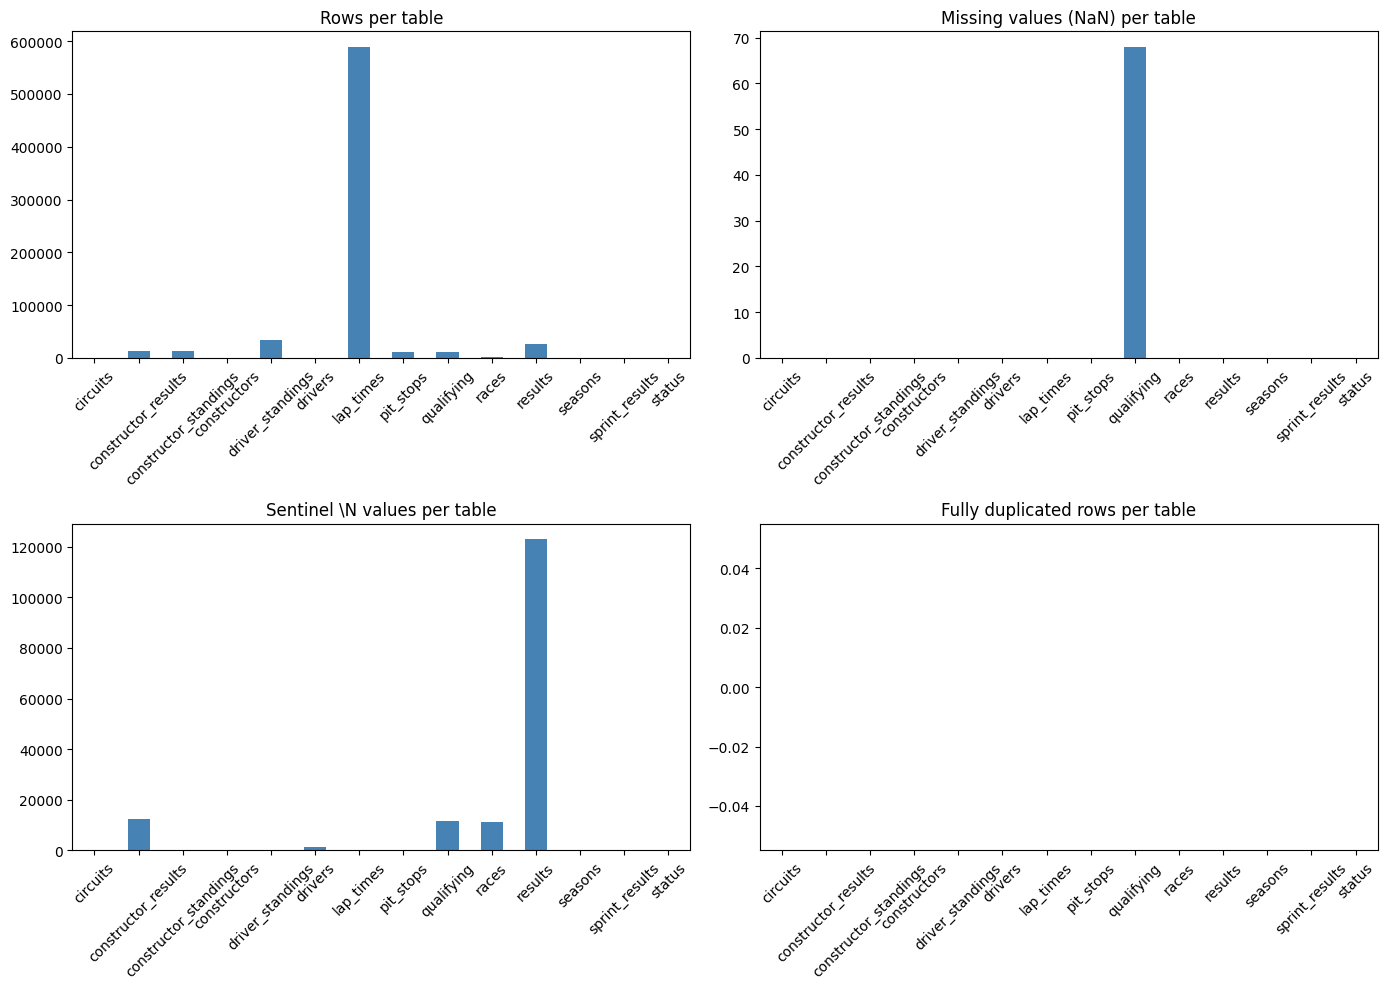

,rows,columns,missing_values,sentinel_values,duplicate_rows
dataset,,,,,
circuits,77,9,0,0,0
constructor_results,12625,5,0,12608,0
constructor_standings,13391,7,0,0,0
constructors,212,5,0,0,0
driver_standings,34863,7,0,0,0
drivers,861,9,0,1559,0
lap_times,589081,6,0,0,0
pit_stops,11371,7,0,0,0
qualifying,10494,9,68,11600,0


In [3]:
def audit_tables(table_dict):
    """Row count, missing values, sentinel strings and fully duplicated rows per table."""
    rows = []
    for name, table in table_dict.items():
        rows.append({
            'dataset': name,
            'rows': len(table),
            'columns': table.shape[1],
            'missing_values': int(table.isna().sum().sum()),
            'sentinel_values': int((table == r'\N').sum().sum()),
            'duplicate_rows': int(table.duplicated().sum()),
        })
    return pd.DataFrame(rows).set_index('dataset')


raw_audit = audit_tables(tables)

raw_results = tables['results']
pair_dupes = raw_results.duplicated(['raceId', 'driverId']).sum()
pair_groups = (raw_results.groupby(['raceId', 'driverId']).size() > 1).sum()
car_dupes = raw_results.duplicated(['raceId', 'number']).sum()
print(f'Duplicate (raceId, driverId) rows in results: {pair_dupes} rows in {pair_groups} pairs')
print(f'Duplicate (raceId, car number) rows in results: {car_dupes}')

print('\nSentinel (\\N) counts per column:')
for name, table in tables.items():
    counts = (table == r'\N').sum()
    counts = counts[counts > 0]
    if len(counts):
        print(f'  {name}: ' + ', '.join(f'{c}={n}' for c, n in counts.items()))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, column, title in zip(
    axes.flat,
    ['rows', 'missing_values', 'sentinel_values', 'duplicate_rows'],
    ['Rows per table', 'Missing values (NaN) per table', 'Sentinel \\N values per table', 'Fully duplicated rows per table']
):
    raw_audit[column].plot(kind='bar', ax=ax, color='steelblue', title=title)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

raw_audit

In [4]:
for key, value in tables.items():
    print(f'###### {key} #######')
    print(value.info())
    print(value.describe())
    display(value.head(5))

###### circuits #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB
None
       circuitId        lat         lng          alt
count  77.000000  77.000000   77.000000    77.000000
mean   39.883117  33.442925    1.076683   247.012987
std    23.001701  22.808866   65.516951   362.738469
min     1.000000 -37.849700 -118.189000    -7.000000
25%    20.000000  32.777400   -9.394170    18.000000
50%    40.000000  40.951700    3.93083

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB
None
       constructorResultsId        raceId  constructorId        points
count          12625.000000  12625.000000   12625.000000  12625.000000
mean            8424.500594    528.235802      45.956119      4.053545
std             5666.310522    314.793555      59.468418      7.862202
min                1.000000      1.000000       1.000000      0.000000
25%             3157.000000    287.000000       6.000000      0.000000
50%  

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


###### constructor_standings #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB
None
       constructorStandingsId        raceId  constructorId        points  \
count            13391.000000  13391.000000   13391.000000  13391.000000   
mean             16982.110821    535.399821      49.603390     37.178515   
std               8868.446172    307.705928      61.213953     84.346048   
min  

...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   resultId        360 non-null    int64 
 1   raceId          360 non-null    int64 
 2   driverId        360 non-null    int64 
 3   constructorId   360 non-null    int64 
 4   number          360 non-null    int64 
 5   grid            360 non-null    int64 
 6   position        360 non-null    object
 7   positionText    360 non-null    object
 8   positionOrder   360 non-null    int64 
 9   points          360 non-null    int64 
 10  laps            360 non-null    int64 
 11  time            360 non-null    object
 12  milliseconds    360 non-null    object
 13  fastestLap      360 non-null    object
 14  fastestLapTime  360 non-null    object
 15  statusId        360 non-null    int64 
dtypes: int64(10), object(6)
memory usage: 45.1+ KB
None
         resultI

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


###### status #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB
None
         statusId
count  139.000000
mean    71.237410
std     41.092434
min      1.000000
25%     35.500000
50%     72.000000
75%    106.500000
max    141.000000


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


### Race-level EDA

Four views of the raw `results` table joined to `races`, `qualifying` and `status`:

1. **Field size and podium share per season** — three podium places divided by the number of entrants sets the base rate of the positive class.
2. **Qualifying coverage per season** — the brief warns about historical qualifying-coverage drift; this decides how we treat qualifying features.
3. **Podium rate by grid position** — the strongest expected pre-race signal.
4. **Share of entries that never started** (did not qualify, did not pre-qualify, withdrew, 107% rule) — these rows are certain non-podiums and matter for the modeling table.

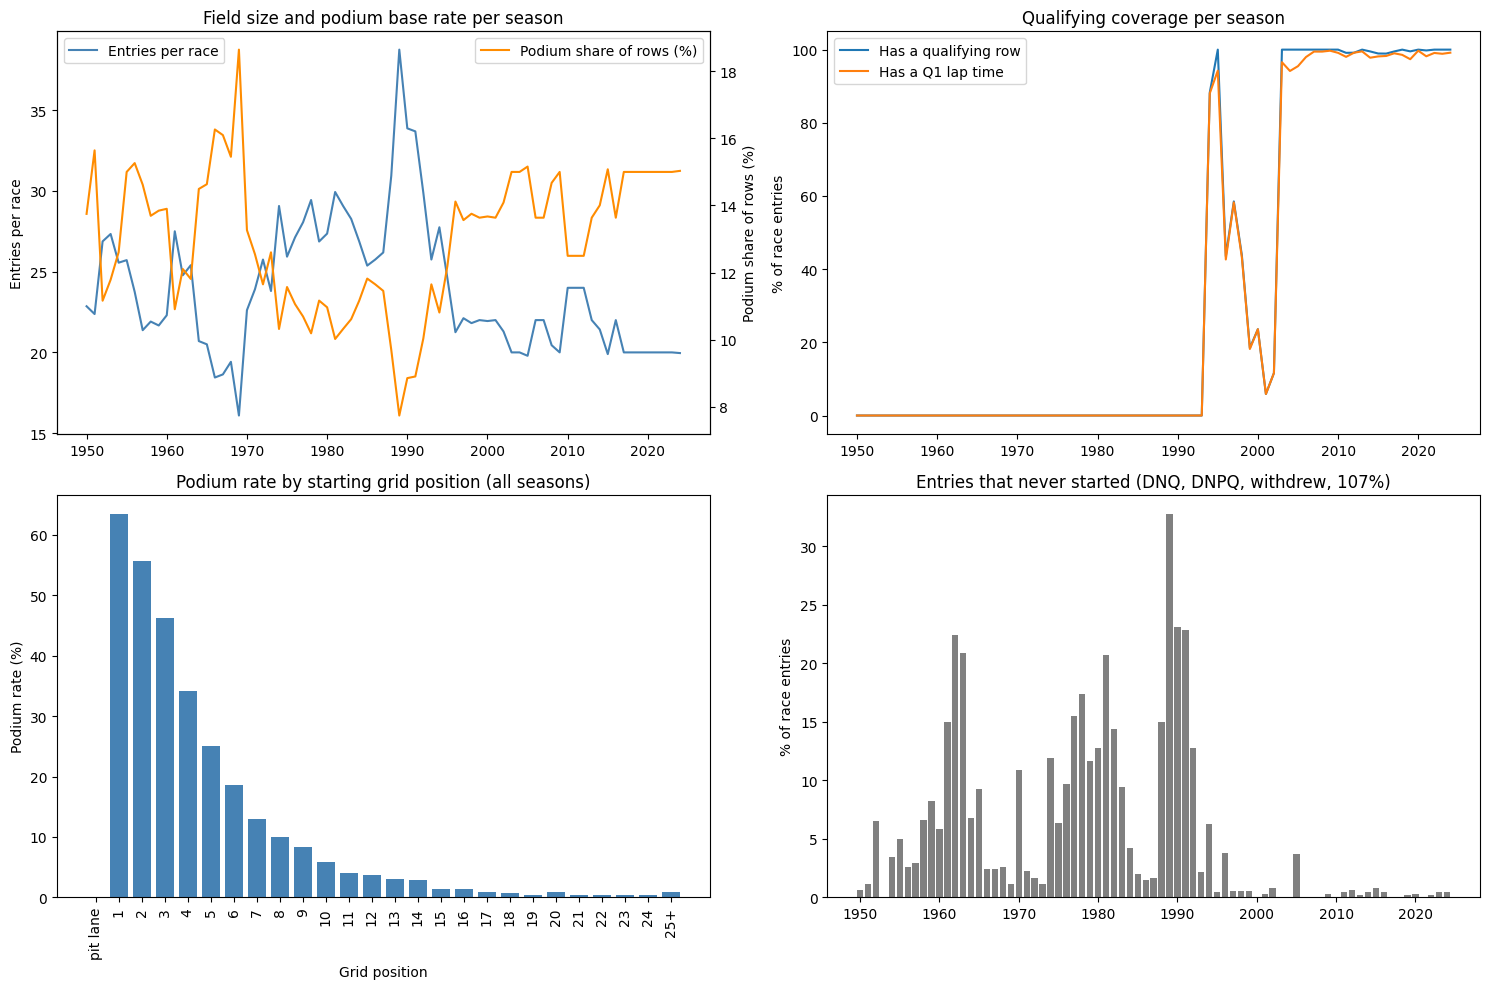

Overall podium share of rows: 0.127
First season with qualifying rows: 1994
Qualifying coverage 1994-2002: 0.44, 2003-2024: 1.00
Pole sitter podium rate: 0.63; grid 10: 0.058; pit-lane start (grid 0): 0.000 over 1638 entries
Entries that never started: 1613 (6.0%), last season with any: 2024


In [5]:
NON_START_STATUSES = ['Did not qualify', 'Did not prequalify', 'Withdrew', '107% Rule']

eda = (
    tables['results'][['resultId', 'raceId', 'driverId', 'grid', 'positionOrder', 'statusId']]
    .merge(tables['races'][['raceId', 'year']], on='raceId')
    .merge(tables['status'], on='statusId')
)
eda['podium'] = eda['positionOrder'] <= 3
eda['non_start'] = eda['status'].isin(NON_START_STATUSES)

qualifying_raw = tables['qualifying'][['raceId', 'driverId', 'q1']].drop_duplicates(['raceId', 'driverId'])
eda = eda.merge(qualifying_raw, on=['raceId', 'driverId'], how='left')
eda['has_qualifying_row'] = eda['q1'].notna()
eda['has_q1_time'] = eda['q1'].notna() & (eda['q1'] != r'\N')

season = eda.groupby('year').agg(
    entries=('resultId', 'size'),
    races=('raceId', 'nunique'),
    podium_rate=('podium', 'mean'),
    qualifying_coverage=('has_qualifying_row', 'mean'),
    q1_time_coverage=('has_q1_time', 'mean'),
    non_start_share=('non_start', 'mean'),
)
season['entries_per_race'] = season['entries'] / season['races']

grid_rate = (
    eda.assign(grid_group=eda['grid'].clip(upper=25))
    .groupby('grid_group')['podium'].agg(['mean', 'size'])
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

ax = axes[0, 0]
ax.plot(season.index, season['entries_per_race'], color='steelblue', label='Entries per race')
ax.set_ylabel('Entries per race')
ax2 = ax.twinx()
ax2.plot(season.index, season['podium_rate'] * 100, color='darkorange', label='Podium share of rows (%)')
ax2.set_ylabel('Podium share of rows (%)')
ax.set_title('Field size and podium base rate per season')
ax.legend(loc='upper left'); ax2.legend(loc='upper right')

ax = axes[0, 1]
ax.plot(season.index, season['qualifying_coverage'] * 100, label='Has a qualifying row')
ax.plot(season.index, season['q1_time_coverage'] * 100, label='Has a Q1 lap time')
ax.set_ylabel('% of race entries'); ax.set_title('Qualifying coverage per season')
ax.legend()

ax = axes[1, 0]
labels = ['pit lane' if g == 0 else ('25+' if g == 25 else str(int(g))) for g in grid_rate.index]
ax.bar(labels, grid_rate['mean'] * 100, color='steelblue')
ax.set_xlabel('Grid position'); ax.set_ylabel('Podium rate (%)')
ax.set_title('Podium rate by starting grid position (all seasons)')
ax.tick_params(axis='x', rotation=90)

ax = axes[1, 1]
ax.bar(season.index, season['non_start_share'] * 100, color='grey')
ax.set_ylabel('% of race entries'); ax.set_title('Entries that never started (DNQ, DNPQ, withdrew, 107%)')

fig.tight_layout()
plt.show()

first_quali_year = season.index[season['qualifying_coverage'] > 0].min()
print(f'Overall podium share of rows: {eda["podium"].mean():.3f}')
print(f'First season with qualifying rows: {first_quali_year}')
print(f'Qualifying coverage 1994-2002: {season.loc[1994:2002, "qualifying_coverage"].mean():.2f}, '
      f'2003-2024: {season.loc[2003:2024, "qualifying_coverage"].mean():.2f}')
print(f'Pole sitter podium rate: {grid_rate.loc[1, "mean"]:.2f}; grid 10: {grid_rate.loc[10, "mean"]:.3f}; '
      f'pit-lane start (grid 0): {grid_rate.loc[0, "mean"]:.3f} over {int(grid_rate.loc[0, "size"])} entries')
print(f'Entries that never started: {eda["non_start"].sum()} ({eda["non_start"].mean():.1%}), '
      f'last season with any: {season.index[season["non_start_share"] > 0].max()}')

**What the raw EDA tells us, and the decisions it drives**

- **Sentinels are the real missing values.** Pandas reports almost no NaN, but `\N` appears 122,887 times in `results` alone and 11,600 times in `qualifying`. → Every table needs `\N → NaN` before any numeric work (2.2).
- **Grain is broken in `results`.** 91 rows repeat a (raceId, driverId) pair, from shared drives in the 1950s–70s. → A deduplication rule is needed (2.5).
- **The positive class is rare and its rate drifts.** About 12.7% of rows are podiums overall; the share falls below 9% in seasons with 30+ entrants (late 1980s) and settles at 15% in the 20-car modern era. → PR-AUC is the right primary metric, and a season-based split keeps the class balance of the test era realistic.
- **Qualifying data starts in 1994 and is patchy until 2003** (44% of entries covered in 1994–2002, ~100% from 2003). → Qualifying features cannot be used for the full history; Section 4 compares keeping all years (no lap times) with keeping only rows that have a Q1 time.
- **Grid position is the dominant pre-race signal.** Pole converts to a podium 63% of the time, grid 10 only 5.8%, and pit-lane / non-starting entries (grid 0) never reached the podium.
- **About 6% of entries never started** (did not qualify, pre-qualify, withdrew, 107% rule), almost all before 2000. They are certain non-podiums at the pre-race cutoff, so we keep them as negatives in the all-years table; the modern (qualifying) table contains almost none.

## 2.2 Sentinels, string normalization and numeric casting

All cleaning happens on copies: `cleaned_tables[name]` is built from `tables[name]` and the raw tables stay untouched.

1. **String normalization** — strip surrounding whitespace in every text column of every table and turn empty strings into NaN.
2. **Sentinels** — the literal `\N` becomes NaN.
3. **Numeric casting** — a column is converted to a number only if no value is lost in the conversion (the count of non-null values is unchanged). This turns `results.position`, `results.milliseconds`, `drivers.number` and similar columns into numbers while leaving text columns such as `positionText` alone.

In [6]:
def normalize_strings(table):
    """Strip whitespace in text columns and turn empty strings into NaN (returns a copy)."""
    table = table.copy()
    for column in table.columns:
        if table[column].dtype == object or pd.api.types.is_string_dtype(table[column]):
            table[column] = table[column].str.strip().replace(r'^\s*$', np.nan, regex=True)
    return table


def convert_column_to_number(table):
    """Cast a column to numeric only when no non-null value is lost (returns a copy)."""
    table = table.copy()
    for column in table.columns:
        new_column = pd.to_numeric(table[column], errors='coerce')
        if new_column.notna().sum() == table[column].notna().sum():
            table[column] = new_column
    return table


cleaned_tables = {
    name: convert_column_to_number(normalize_strings(table).replace(r'\N', np.nan))
    for name, table in tables.items()
}

remaining_sentinels = sum(int((t == r'\N').sum().sum()) for t in cleaned_tables.values())
raw_untouched = all((tables[n] == r'\N').sum().sum() == raw_audit.loc[n, 'sentinel_values'] for n in tables)
print('Sentinels left after cleaning:', remaining_sentinels)
print('Raw tables unchanged:', raw_untouched)

pd.DataFrame({
    'raw dtype': tables['results'].dtypes.astype(str),
    'cleaned dtype': cleaned_tables['results'].dtypes.astype(str),
})

Sentinels left after cleaning: 0
Raw tables unchanged: True


,raw dtype,cleaned dtype
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,object,float64
grid,int64,int64
position,object,float64
positionText,object,object
positionOrder,int64,int64
points,float64,float64


## 2.3 Semantic typing of dates and durations

- **Dates** — `races.date`, every session date (`fp1_date` … `sprint_date`) and `drivers.dob` become `datetime64`; session start times become `timedelta`.
- **Durations** — every lap-time style string becomes numeric seconds with one parser that handles `ss.sss`, `m:ss.sss` and `h:mm:ss.sss`: qualifying `q1–q3`, `lap_times.time`, `pit_stops.duration` and `fastestLapTime` in `results` and `sprint_results`.
- `results.time` is left as text on purpose: it holds the winner's total time but a **gap** (`+5.478`) for everyone else, so it is not one quantity; the numeric `milliseconds` column already covers it.

The parser is checked against the `milliseconds` columns that the dataset provides for lap times and pit stops.

In [7]:
def to_seconds(text):
    """'23.426' -> 23.426, '1:27.452' -> 87.452, '1:34:50.616' -> 5690.616; anything else -> NaN."""
    if pd.isna(text):
        return np.nan
    if isinstance(text, (int, float, np.number)):
        return float(text)
    try:
        parts = [float(part) for part in str(text).split(':')]
    except ValueError:
        return np.nan
    seconds = 0.0
    for part in parts:
        seconds = seconds * 60 + part
    return seconds


races_clean = cleaned_tables['races']
for column in ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']:
    races_clean[column] = pd.to_datetime(races_clean[column])
for column in ['time', 'fp1_time', 'fp2_time', 'fp3_time', 'quali_time', 'sprint_time']:
    races_clean[column] = pd.to_timedelta(races_clean[column])
cleaned_tables['drivers']['dob'] = pd.to_datetime(cleaned_tables['drivers']['dob'])

duration_columns = {
    'qualifying': ['q1', 'q2', 'q3'],
    'lap_times': ['time'],
    'pit_stops': ['duration'],
    'results': ['fastestLapTime'],
    'sprint_results': ['fastestLapTime'],
}
for table_name, columns in duration_columns.items():
    for column in columns:
        cleaned_tables[table_name][column] = cleaned_tables[table_name][column].map(to_seconds).astype(float)

lap_check = (cleaned_tables['lap_times']['time'] - cleaned_tables['lap_times']['milliseconds'] / 1000).abs().max()
pit_check = (cleaned_tables['pit_stops']['duration'] - cleaned_tables['pit_stops']['milliseconds'] / 1000).abs().max()
print(f'Largest disagreement with the milliseconds column: lap times {lap_check:.3f} s, pit stops {pit_check:.3f} s')

typed = pd.DataFrame([
    (f'{t}.{c}', str(tables[t][c].dtype), str(cleaned_tables[t][c].dtype), tables[t][c].iloc[0], cleaned_tables[t][c].iloc[0])
    for t, cols in {**duration_columns, 'races': ['date', 'time', 'quali_date'], 'drivers': ['dob']}.items() for c in cols
], columns=['column', 'raw dtype', 'clean dtype', 'raw example', 'clean example'])
typed

Largest disagreement with the milliseconds column: lap times 0.000 s, pit stops 0.000 s


,column,raw dtype,clean dtype,raw example,clean example
0,qualifying.q1,object,float64,1:26.572,86.572
1,qualifying.q2,object,float64,1:25.187,85.187
2,qualifying.q3,object,float64,1:26.714,86.714
3,lap_times.time,object,float64,1:38.109,98.109
4,pit_stops.duration,object,float64,26.898,26.898
5,results.fastestLapTime,object,float64,1:27.452,87.452
6,sprint_results.fastestLapTime,object,float64,1:30.013,90.013
7,races.date,object,datetime64[ns],2009-03-29,2009-03-29 00:00:00
8,races.time,object,timedelta64[ns],06:00:00,0 days 06:00:00
9,races.quali_date,object,datetime64[ns],\N,NaT


## 2.4 Referential integrity

**Primary keys** must be unique and non-null. `lap_times` and `pit_stops` have no single-column key, so we build composite keys (race, driver, lap) and (race, driver, stop).

**Foreign keys** must reconcile: every id that points to another table has to exist there.

In [8]:
cleaned_tables['lap_times']['lapId'] = (
    cleaned_tables['lap_times']['raceId'].astype(str) + '_'
    + cleaned_tables['lap_times']['driverId'].astype(str) + '_'
    + cleaned_tables['lap_times']['lap'].astype(str)
)
cleaned_tables['pit_stops']['stopId'] = (
    cleaned_tables['pit_stops']['raceId'].astype(str) + '_'
    + cleaned_tables['pit_stops']['driverId'].astype(str) + '_'
    + cleaned_tables['pit_stops']['stop'].astype(str)
)

primary_keys = {
    'circuits': 'circuitId', 'constructor_results': 'constructorResultsId',
    'constructor_standings': 'constructorStandingsId', 'constructors': 'constructorId',
    'driver_standings': 'driverStandingsId', 'drivers': 'driverId', 'lap_times': 'lapId',
    'pit_stops': 'stopId', 'qualifying': 'qualifyId', 'races': 'raceId', 'results': 'resultId',
    'seasons': 'year', 'sprint_results': 'resultId', 'status': 'statusId',
}

pk_report = pd.DataFrame([
    {
        'table': table_name,
        'key': key,
        'unique': cleaned_tables[table_name][key].is_unique,
        'non_null': bool(cleaned_tables[table_name][key].notna().all()),
    }
    for table_name, key in primary_keys.items()
])
pk_report

,table,key,unique,non_null
0,circuits,circuitId,True,True
1,constructor_results,constructorResultsId,True,True
2,constructor_standings,constructorStandingsId,True,True
3,constructors,constructorId,True,True
4,driver_standings,driverStandingsId,True,True
5,drivers,driverId,True,True
6,lap_times,lapId,True,True
7,pit_stops,stopId,True,True
8,qualifying,qualifyId,True,True
9,races,raceId,True,True


In [9]:
foreign_keys = [
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    ('races', 'circuitId', 'circuits', 'circuitId'),
    ('races', 'year', 'seasons', 'year'),
    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),
    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
]

fk_report = pd.DataFrame([
    {
        'child': f'{table}.{column}',
        'parent': f'{parent}.{parent_key}',
        'orphans': int((~cleaned_tables[table][column].isin(cleaned_tables[parent][parent_key])).sum()),
    }
    for table, column, parent, parent_key in foreign_keys
])
print('Total orphan foreign-key values:', fk_report['orphans'].sum())
fk_report

Total orphan foreign-key values: 0


,child,parent,orphans
0,constructor_results.raceId,races.raceId,0
1,constructor_results.constructorId,constructors.constructorId,0
2,constructor_standings.raceId,races.raceId,0
3,constructor_standings.constructorId,constructors.constructorId,0
4,driver_standings.raceId,races.raceId,0
5,driver_standings.driverId,drivers.driverId,0
6,lap_times.raceId,races.raceId,0
7,lap_times.driverId,drivers.driverId,0
8,pit_stops.raceId,races.raceId,0
9,pit_stops.driverId,drivers.driverId,0


## 2.5 Fixing the grain: one row per (raceId, driverId)

Each row of the modeling table is one prediction, so `(raceId, driverId)` must be unique in `results`. Shared drives before 1960 break this in two ways, and we handle each with an explicit rule.

**Rule 1 — one driver, two cars in the same race (91 rows, 85 pairs, 1950–1978).** A driver who took over a teammate's car gets one result row per car. We keep the row with the **best `positionOrder`**, i.e. the car with which the driver was officially classified highest. Rationale: it is the row the championship records credit to that driver, and keeping exactly one row per driver is what the grain requires. Trade-off: where one of the two cars reached the podium, the kept row is the podium row, so positives are very slightly favoured in those few 1950s races.

**Rule 2 — one car credited to two or more drivers (134 rows, 1950–1981).** When drivers shared a car, each of them is given the same finishing position. The EDA showed 18 races that end up with 4–5 "podium" rows instead of 3. We keep the driver with the best `positionOrder` for each car number in a race, so that every race has exactly three podium rows, the same as the target definition implies. Rows with a missing car number are never treated as duplicates of each other.

Both rules only touch seasons up to 1981, so they do not affect the qualifying-era table used for the final models.

In [10]:
results_before_dedup = cleaned_tables['results'].copy()

sorted_results = results_before_dedup.sort_values(['raceId', 'driverId', 'positionOrder'])
rule1_drop = sorted_results[sorted_results.duplicated(['raceId', 'driverId'], keep='first')]
results_after_rule1 = results_before_dedup.drop(rule1_drop.index)

rule1_years = cleaned_tables['races'].set_index('raceId').loc[rule1_drop['raceId'], 'year']
print(f'Rule 1 removed {len(rule1_drop)} rows ({rule1_years.min()}-{rule1_years.max()})')
rule1_drop.head()

Rule 1 removed 91 rows (1950-1978)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17743,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17963,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23
18062,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6


In [11]:
with_number = results_after_rule1[results_after_rule1['number'].notna()]
sorted_cars = with_number.sort_values(['raceId', 'number', 'positionOrder'])
rule2_drop = sorted_cars[sorted_cars.duplicated(['raceId', 'number'], keep='first')]

cleaned_tables['results'] = results_after_rule1.drop(rule2_drop.index)

rule2_years = cleaned_tables['races'].set_index('raceId').loc[rule2_drop['raceId'], 'year']
print(f'Rule 2 removed {len(rule2_drop)} rows ({rule2_years.min()}-{rule2_years.max()}); '
      f'{int((rule2_drop["grid"] > 0).sum())} of them had a grid slot')


def podium_rows_per_race(results_table):
    return results_table[results_table['positionOrder'] <= 3].groupby('raceId').size()


grain_check = pd.DataFrame({
    'stage': ['raw', 'after rule 1', 'after rule 2'],
    'rows': [len(results_before_dedup), len(results_after_rule1), len(cleaned_tables['results'])],
    'duplicate (raceId, driverId)': [
        int(t.duplicated(['raceId', 'driverId']).sum())
        for t in [results_before_dedup, results_after_rule1, cleaned_tables['results']]
    ],
    'races without exactly 3 podium rows': [
        int((podium_rows_per_race(t) != 3).sum())
        for t in [results_before_dedup, results_after_rule1, cleaned_tables['results']]
    ],
})
grain_check

Rule 2 removed 134 rows (1950-1981); 101 of them had a grid slot


,stage,rows,"duplicate (raceId, driverId)",races without exactly 3 podium rows
0,raw,26759,91,18
1,after rule 1,26668,0,18
2,after rule 2,26534,0,0


## 2.6 EDA after cleaning: what the cleaning changed

The same audit is repeated on `cleaned_tables` and shown next to the raw numbers. The first panel shows the main effect of cleaning: in the raw tables pandas sees almost no missing values because they hide behind `\N`; after cleaning the true amount of missing data is visible (and handled explicitly in Section 4).

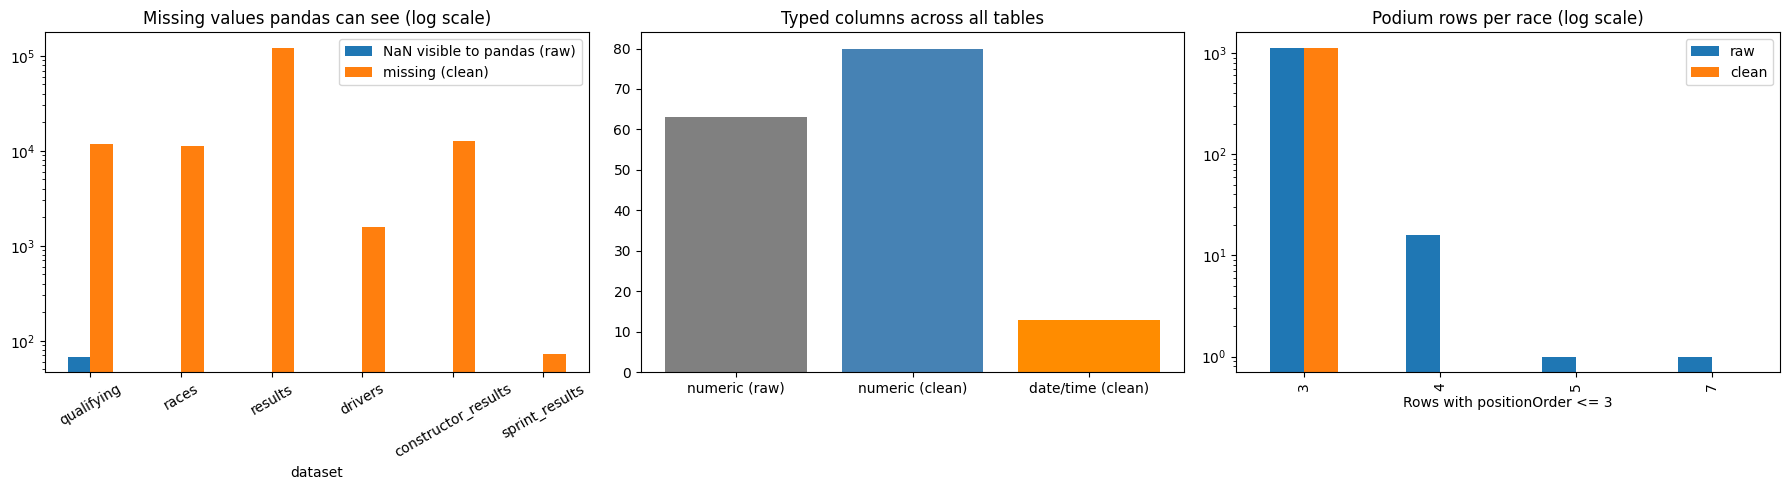

qualifying.q1: raw parses as numbers for 0 rows (text like "1:26.572" does not); clean has 10338 numeric values, range 53.9-1002.6 s


,rows (raw),rows (clean),NaN visible to pandas (raw),missing (clean),sentinels (raw),sentinels (clean)
dataset,,,,,,
circuits,77,77,0,0,0,0
constructor_results,12625,12625,0,12608,12608,0
constructor_standings,13391,13391,0,0,0,0
constructors,212,212,0,0,0,0
driver_standings,34863,34863,0,0,0,0
drivers,861,861,0,1559,1559,0
lap_times,589081,589081,0,0,0,0
pit_stops,11371,11371,0,0,0,0
qualifying,10494,10494,68,11668,11600,0


In [12]:
clean_audit = audit_tables(cleaned_tables)

comparison = pd.DataFrame({
    'rows (raw)': raw_audit['rows'],
    'rows (clean)': clean_audit['rows'],
    'NaN visible to pandas (raw)': raw_audit['missing_values'],
    'missing (clean)': clean_audit['missing_values'],
    'sentinels (raw)': raw_audit['sentinel_values'],
    'sentinels (clean)': clean_audit['sentinel_values'],
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
focus = ['qualifying', 'races', 'results', 'drivers', 'constructor_results', 'sprint_results']
comparison.loc[focus, ['NaN visible to pandas (raw)', 'missing (clean)']].plot(kind='bar', ax=axes[0], logy=True)
axes[0].set_title('Missing values pandas can see (log scale)')
axes[0].tick_params(axis='x', rotation=30)

numeric_before = sum(pd.api.types.is_numeric_dtype(t[c]) for t in tables.values() for c in t.columns)
numeric_after = sum(pd.api.types.is_numeric_dtype(t[c]) for t in cleaned_tables.values() for c in t.columns)
temporal_after = sum(
    pd.api.types.is_datetime64_any_dtype(t[c]) or pd.api.types.is_timedelta64_dtype(t[c])
    for t in cleaned_tables.values() for c in t.columns
)
axes[1].bar(['numeric (raw)', 'numeric (clean)', 'date/time (clean)'], [numeric_before, numeric_after, temporal_after],
            color=['grey', 'steelblue', 'darkorange'])
axes[1].set_title('Typed columns across all tables')

before_counts = podium_rows_per_race(results_before_dedup).value_counts().sort_index()
after_counts = podium_rows_per_race(cleaned_tables['results']).value_counts().sort_index()
pd.DataFrame({'raw': before_counts, 'clean': after_counts}).fillna(0).plot(kind='bar', ax=axes[2], logy=True)
axes[2].set_title('Podium rows per race (log scale)')
axes[2].set_xlabel('Rows with positionOrder <= 3')

fig.tight_layout()
plt.show()

q_raw = pd.to_numeric(tables['qualifying']['q1'].replace(r'\N', np.nan), errors='coerce')
print(f'qualifying.q1: raw parses as numbers for {q_raw.notna().sum()} rows (text like "1:26.572" does not); '
      f'clean has {cleaned_tables["qualifying"]["q1"].notna().sum()} numeric values, '
      f'range {cleaned_tables["qualifying"]["q1"].min():.1f}-{cleaned_tables["qualifying"]["q1"].max():.1f} s')
comparison

# 3. Data-Engineering Questions

All three answers join several tables (`results`, `races`, `circuits`, `qualifying`, `drivers`, `status`, `constructors`). Each subsection states the grain it works at, how missing data is handled, and whether the pre-race cutoff matters.

## Q1. Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era?

**Approach.**
- *Grain:* one driver in one race. A **front-row start** is a driver starting from grid slot 1 or 2; the **conversion rate** of a circuit is podiums ÷ front-row starts there. Raw counts would mostly reward circuits that hosted many races.
- *Grid vs qualifying:* the grid is the qualifying order after penalties, so we compute the rate twice: front row by **grid** (`results.grid`) and front row by **qualifying** (`qualifying.position`).
- *Window and missingness:* qualifying positions exist only from 1994, so both definitions use 1994–2024, split into **1994–2013** and **2014–2024** (hybrid era and after). Circuits need at least 10 front-row starts in an era to be ranked.

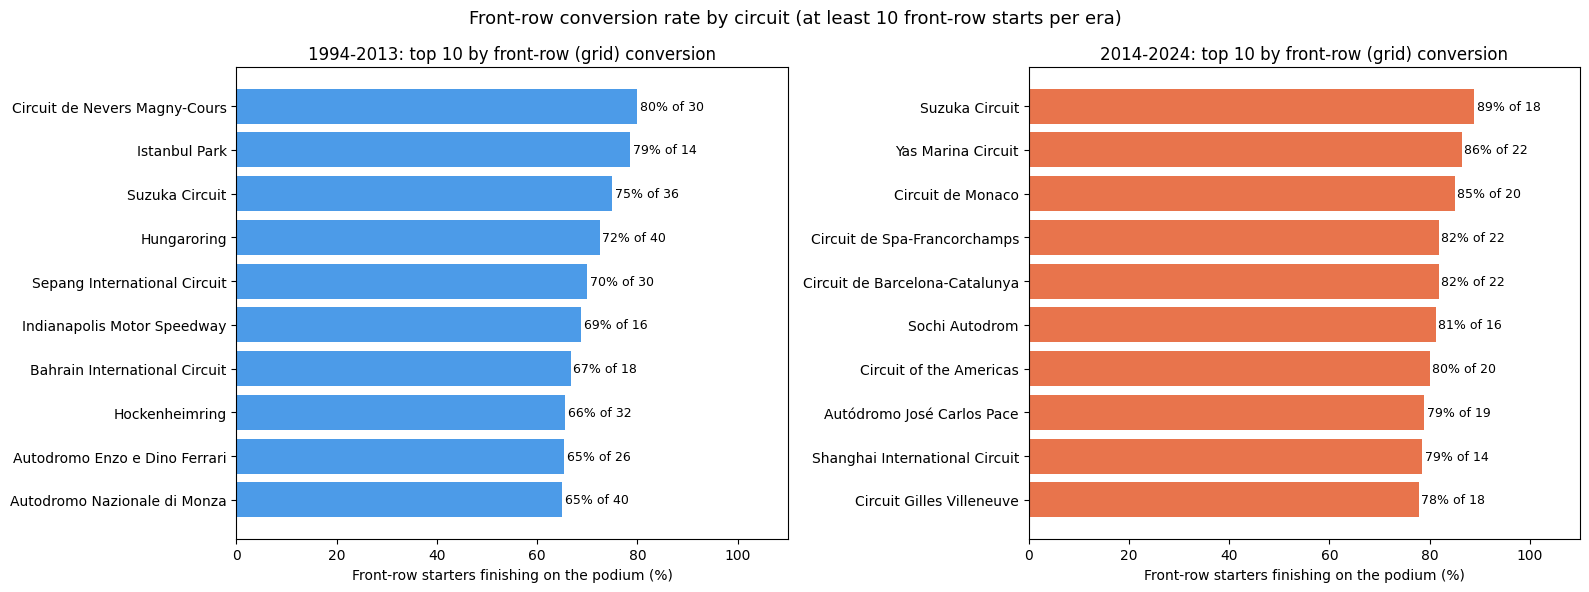

Circuits ranked in both eras: 15; Spearman rank correlation between eras: -0.07


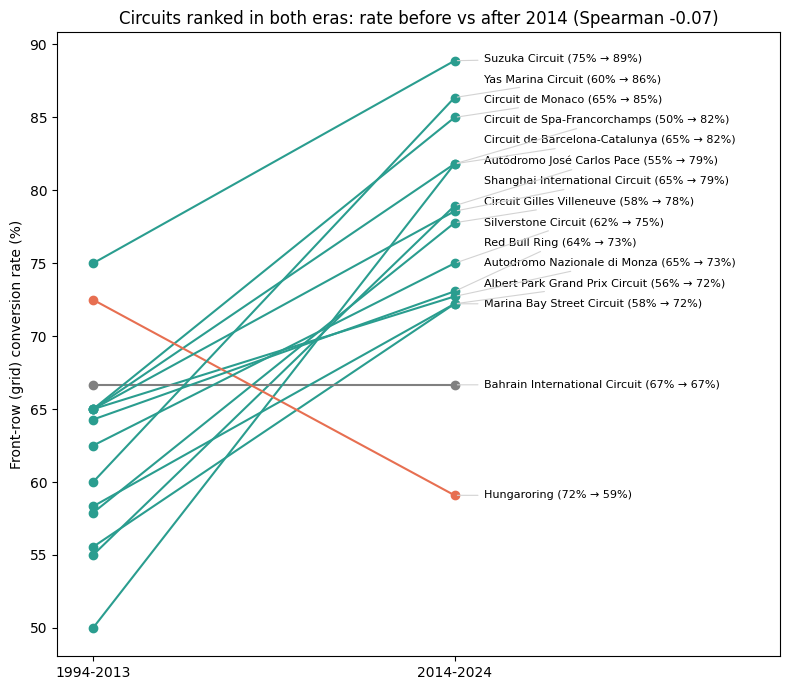

Qualified on the front row but started elsewhere (penalties, pit-lane starts): 38 cases, podium rate 29%

Overall conversion by definition and era:
           grid front row  qualifying front row
era                                            
1994-2013           0.642                 0.647
2014-2024           0.760                 0.737

Top 5 by qualifying front row, per era:
1994-2013 Circuit de Nevers Magny-Cours 89%, Istanbul Park 79%, Suzuka Circuit 77%, Shanghai International Circuit 70%, Hockenheimring 68%
2014-2024 Suzuka Circuit 89%, Circuit de Monaco 85%, Circuit de Barcelona-Catalunya 82%, Circuit de Spa-Francorchamps 82%, Yas Marina Circuit 82%


era,rate % 1994-2013,rate % 2014-2024,rank 1994-2013,rank 2014-2024,rank change
name,,,,,
Suzuka Circuit,75.0,88.9,1,1,0
Yas Marina Circuit,60.0,86.4,10,2,8
Circuit de Monaco,65.0,85.0,4,3,1
Circuit de Barcelona-Catalunya,65.0,81.8,4,4,0
Circuit de Spa-Francorchamps,50.0,81.8,15,4,11
Autódromo José Carlos Pace,55.0,78.9,14,6,8
Shanghai International Circuit,65.0,78.6,4,7,-3
Circuit Gilles Villeneuve,57.9,77.8,12,8,4
Silverstone Circuit,62.5,75.0,9,9,0


In [13]:
front_row = (
    cleaned_tables['results'][['raceId', 'driverId', 'grid', 'positionOrder']]
    .merge(cleaned_tables['races'][['raceId', 'year', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
    .merge(
        cleaned_tables['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'}),
        on=['raceId', 'driverId'], how='left'
    )
)
front_row = front_row[front_row['year'] >= 1994].copy()
front_row['podium'] = front_row['positionOrder'] <= 3
front_row['era'] = np.where(front_row['year'] >= 2014, '2014-2024', '1994-2013')

MIN_STARTS = 10


def conversion_table(data, position_column):
    starters = data[data[position_column].isin([1, 2])]
    table = (
        starters.groupby(['era', 'name'])['podium']
        .agg(front_row_starts='size', podiums='sum', rate='mean')
        .reset_index()
    )
    return table[table['front_row_starts'] >= MIN_STARTS]


by_grid = conversion_table(front_row, 'grid')
by_quali = conversion_table(front_row, 'quali_position')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, era, color in zip(axes, ['1994-2013', '2014-2024'], ['#4c9be8', '#e8744c']):
    top = by_grid[by_grid['era'] == era].nlargest(10, 'rate').sort_values('rate')
    ax.barh(top['name'], top['rate'] * 100, color=color)
    for i, (rate, n) in enumerate(zip(top['rate'], top['front_row_starts'])):
        ax.text(rate * 100 + 0.5, i, f'{rate:.0%} of {n}', va='center', fontsize=9)
    ax.set_title(f'{era}: top 10 by front-row (grid) conversion')
    ax.set_xlabel('Front-row starters finishing on the podium (%)')
    ax.set_xlim(0, 110)
fig.suptitle(f'Front-row conversion rate by circuit (at least {MIN_STARTS} front-row starts per era)', fontsize=13)
fig.tight_layout()
plt.show()

# Ranking change between eras, for circuits ranked in both
wide = by_grid.pivot(index='name', columns='era', values='rate').dropna()
rank_change = wide.rank(ascending=False, method='min').astype(int).rename(columns=lambda c: f'rank {c}')
rank_change = wide.mul(100).round(1).rename(columns=lambda c: f'rate % {c}').join(rank_change)
rank_change['rank change'] = rank_change['rank 1994-2013'] - rank_change['rank 2014-2024']
spearman = wide['1994-2013'].corr(wide['2014-2024'], method='spearman')
print(f'Circuits ranked in both eras: {len(wide)}; Spearman rank correlation between eras: {spearman:.2f}')

fig, ax = plt.subplots(figsize=(8, 7))
for name, row in wide.iterrows():
    change = row['2014-2024'] - row['1994-2013']
    color = '#2a9d8f' if change > 0.05 else ('#e76f51' if change < -0.05 else 'grey')
    ax.plot([0, 1], [row['1994-2013'] * 100, row['2014-2024'] * 100], marker='o', color=color)
label_y = wide['2014-2024'].mul(100).sort_values()
placed = []
for name, y in label_y.items():  # spread labels so they do not overlap
    y = max(y, placed[-1] + 1.4) if placed else y
    placed.append(y)
    true_y = wide.loc[name, '2014-2024'] * 100
    ax.annotate(f'{name} ({wide.loc[name, "1994-2013"]:.0%} → {wide.loc[name, "2014-2024"]:.0%})',
                xy=(1, true_y), xytext=(1.08, y), va='center', fontsize=8,
                arrowprops=dict(arrowstyle='-', color='lightgrey', lw=0.8))
ax.set_xticks([0, 1]); ax.set_xticklabels(['1994-2013', '2014-2024']); ax.set_xlim(-0.1, 1.9)
ax.set_ylabel('Front-row (grid) conversion rate (%)')
ax.set_title(f'Circuits ranked in both eras: rate before vs after 2014 (Spearman {spearman:.2f})')
fig.tight_layout()
plt.show()

overall = front_row.assign(
    grid_front=front_row['grid'].isin([1, 2]),
    quali_front=front_row['quali_position'].isin([1, 2]),
)
summary_q1 = pd.DataFrame({
    'grid front row': overall[overall['grid_front']].groupby('era')['podium'].mean(),
    'qualifying front row': overall[overall['quali_front']].groupby('era')['podium'].mean(),
})
moved = overall[overall['quali_front'] & ~overall['grid_front']]
print(f'Qualified on the front row but started elsewhere (penalties, pit-lane starts): {len(moved)} cases, '
      f'podium rate {moved["podium"].mean():.0%}')
print('\nOverall conversion by definition and era:')
print(summary_q1.round(3))

print('\nTop 5 by qualifying front row, per era:')
for era in ['1994-2013', '2014-2024']:
    print(era, ', '.join(f"{r['name']} {r['rate']:.0%}" for _, r in by_quali[by_quali['era'] == era].nlargest(5, 'rate').iterrows()))

rank_change.sort_values('rank 2014-2024')

**Answer to Q1.**

- **1994–2013:** Magny-Cours (80% of 30 front-row starts), Istanbul Park (79%), Suzuka (75%) and the Hungaroring (72%) converted a front-row start into a podium most often.
- **2014–2024:** Suzuka (89% of 18), Yas Marina (86%), Monaco (85%), Spa and Barcelona (82%) lead.
- **The ranking changes a lot.** Among the 15 circuits ranked in both eras, the Spearman rank correlation is −0.07, i.e. essentially no relation. Front-row conversion rose almost everywhere (64% → 76% overall), consistent with the dominant Mercedes and Red Bull cars of the hybrid and ground-effect eras. The Hungaroring is the clear exception, falling from 72% to 59% and from 2nd to last.
- **Qualifying vs grid.** By qualifying position the overall rates are almost the same (65% and 74%) and the top circuits largely agree. But the 38 drivers who qualified on the front row and then started elsewhere (grid penalties, pit-lane starts) reached the podium only 29% of the time, so grid position, not qualifying position, is what carries the conversion.

*Why two eras:* the brief asks whether the ranking changes after the 2014 hybrid era, so we compare everything before 2014 (from 1994, when qualifying data starts) with everything from 2014. Splitting 2014–2021 from 2022–2024 would leave only three seasons, too few front-row starts per circuit to rank.

*Grain:* driver–race. *Missingness:* qualifying positions are missing before 1994, which is why the window starts there; circuits with fewer than 10 front-row starts in an era are not ranked. *Cutoff:* grid and qualifying position are both known before the race, and the podium is the outcome being counted, so there is no leakage in this descriptive question.

## Q2. Do drivers podium more often at a home circuit, after controlling for starting position?

**Approach.** A driver is "at home" when their nationality maps to the circuit's country (a mapping table is needed because `drivers.nationality` holds adjectives such as "British" while `circuits.country` holds names such as "UK"; both "USA" and "United States" appear for American circuits). To control for starting position we compare home and away drivers **inside the same grid band** (P1, P2, P3, P4–5, …), then compute how often home drivers *would* have reached the podium if they converted like away drivers from the same bands. The difference between actual and expected home podium rates is the grid-adjusted home effect, with a 95% bootstrap confidence interval.

*Exclusions:* pit-lane / non-starting entries (grid 0) and the **Indianapolis 500 (1950–1960)**, which counted for the championship but was entered almost only by American oval specialists and would inflate the American "home" sample.

In [14]:
nat_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'East Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela',
}


circuit_country_alias = {'United States': 'USA'}  # the Las Vegas Strip circuit uses the long form

home_data = (
    cleaned_tables['results'][['raceId', 'positionOrder', 'grid', 'driverId']]
    .merge(cleaned_tables['races'][['raceId', 'circuitId', 'year']], on='raceId')
    .merge(cleaned_tables['drivers'][['driverId', 'nationality']], on='driverId')
    .merge(cleaned_tables['circuits'][['circuitId', 'circuitRef', 'country']], on='circuitId')
)
home_data['country'] = home_data['country'].replace(circuit_country_alias)
home_data['driver_country'] = home_data['nationality'].map(nat_to_country)

unmapped = sorted(home_data.loc[home_data['driver_country'].isna(), 'nationality'].unique())
print('Nationalities without a country mapping:', unmapped if unmapped else 'none')

indy_500 = (home_data['circuitRef'] == 'indianapolis') & (home_data['year'] <= 1960)
print(f'Indianapolis 500 rows excluded: {int(indy_500.sum())}')
home_data = home_data[~indy_500]

Nationalities without a country mapping: none
Indianapolis 500 rows excluded: 350


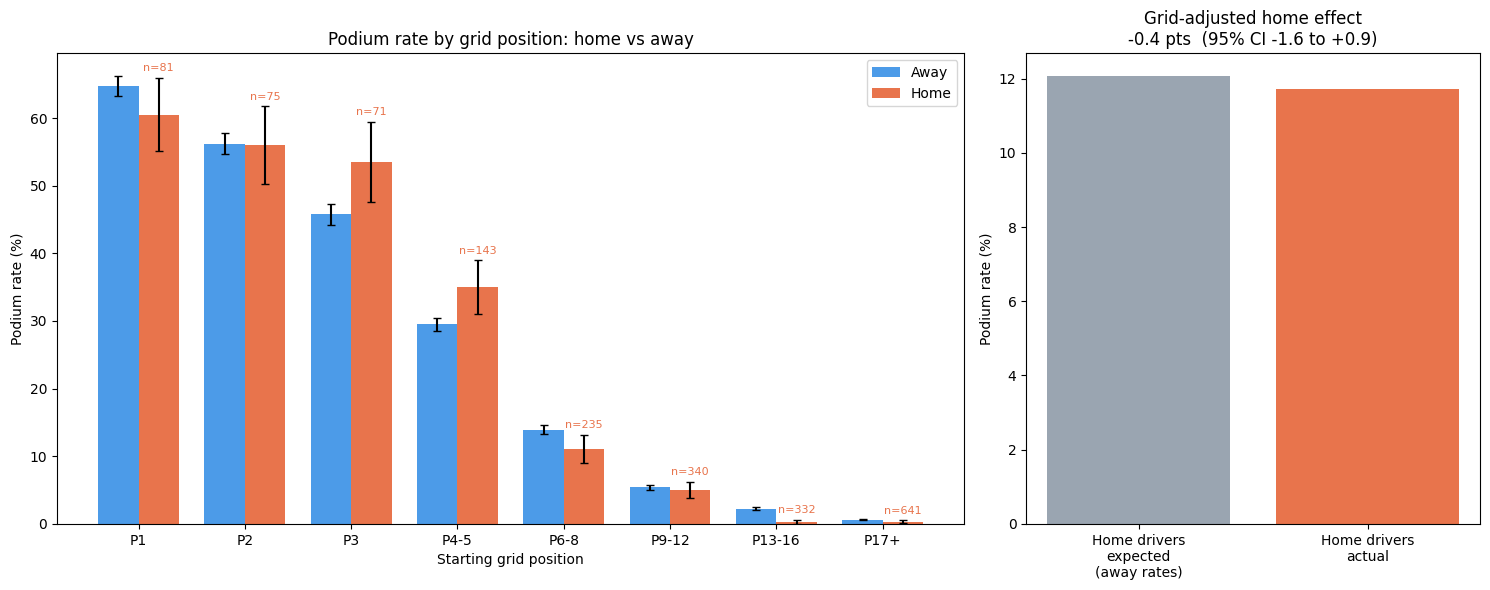

All seasons: home actual 0.117, expected 0.121, effect -0.4 pts (95% CI -1.6 to +0.9); home entries: 1918
1994-2024 only: effect -2.6 pts (95% CI -4.9 to -0.6); home entries: 593


In [15]:
d = home_data.copy()
d = d[d['grid'] >= 1]                                  # drop pit-lane starts (grid == 0)
d['home']   = d['driver_country'] == d['country']
d['podium'] = d['positionOrder'] <= 3

bins   = [0, 1, 2, 3, 5, 8, 12, 16, 40]
labels = ['P1', 'P2', 'P3', 'P4-5', 'P6-8', 'P9-12', 'P13-16', 'P17+']
d['grid_bin'] = pd.cut(d['grid'], bins=bins, labels=labels)

# podium rate per grid bin, split by home/away
g = (d.groupby(['grid_bin', 'home'], observed=True)['podium']
       .agg(rate='mean', k='sum', n='size')
       .unstack('home'))

# standard error for error bars
def se(rate, n): return np.sqrt(rate * (1 - rate) / n)

# grid-adjusted effect: actual home podium rate vs the rate home drivers
# would have had if they converted like away drivers from the same grid bin
def adjusted_effect(data):
    t = data.groupby(['grid_bin', 'home'], observed=True)['podium'].agg(['mean', 'size']).unstack('home')
    t = t.dropna()
    w = t[('size', True)]
    expected = (t[('mean', False)] * w).sum() / w.sum()
    actual   = (t[('mean', True)]  * w).sum() / w.sum()
    return actual, expected

actual, expected = adjusted_effect(d)

# bootstrap CI for (actual - expected)
rng = np.random.default_rng(0)
boots = []
for _ in range(500):
    s = d.sample(len(d), replace=True, random_state=int(rng.integers(1e9)))
    a, e = adjusted_effect(s)
    boots.append(a - e)
lo, hi = np.percentile(boots, [2.5, 97.5])

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1]})

x = np.arange(len(g))
wd = 0.38
away_rate, home_rate = g[('rate', False)] * 100, g[('rate', True)] * 100
away_err = se(g[('rate', False)], g[('n', False)]) * 100
home_err = se(g[('rate', True)],  g[('n', True)])  * 100

ax1.bar(x - wd/2, away_rate, wd, yerr=away_err, color='#4c9be8', label='Away', capsize=3)
ax1.bar(x + wd/2, home_rate, wd, yerr=home_err, color='#e8744c', label='Home', capsize=3)
for i, (_, r) in enumerate(g.iterrows()):
    ax1.text(i + wd/2, home_rate.iloc[i] + home_err.iloc[i] + 1, f"n={int(r[('n', True)])}",
             ha='center', fontsize=8, color='#e8744c')
ax1.set_xticks(x)
ax1.set_xticklabels(g.index)
ax1.set_xlabel('Starting grid position')
ax1.set_ylabel('Podium rate (%)')
ax1.set_title('Podium rate by grid position: home vs away')
ax1.legend()

ax2.bar(['Home drivers\nexpected\n(away rates)', 'Home drivers\nactual'],
        [expected * 100, actual * 100], color=['#9aa5b1', '#e8744c'])
ax2.set_ylabel('Podium rate (%)')
ax2.set_title(f'Grid-adjusted home effect\n{(actual-expected)*100:+.1f} pts  (95% CI {lo*100:+.1f} to {hi*100:+.1f})')

plt.tight_layout()
plt.show()

modern = d[d['year'] >= 1994]
actual_modern, expected_modern = adjusted_effect(modern)
print(f'All seasons: home actual {actual:.3f}, expected {expected:.3f}, effect {(actual - expected) * 100:+.1f} pts '
      f'(95% CI {lo * 100:+.1f} to {hi * 100:+.1f}); home entries: {int(d["home"].sum())}')
modern_boots = []
for _ in range(500):
    sample = modern.sample(len(modern), replace=True, random_state=int(rng.integers(1e9)))
    a, e = adjusted_effect(sample)
    modern_boots.append(a - e)
m_lo, m_hi = np.percentile(modern_boots, [2.5, 97.5])
print(f'1994-2024 only: effect {(actual_modern - expected_modern) * 100:+.1f} pts '
      f'(95% CI {m_lo * 100:+.1f} to {m_hi * 100:+.1f}); home entries: {int(modern["home"].sum())}')

**Answer to Q2.** No — there is no home advantage once starting position is taken into account.

- Across all seasons (Indianapolis 500 excluded, 1,918 home entries), home drivers reached the podium 11.7% of the time, against 12.1% expected from away drivers starting in the same grid bands: **−0.4 points (95% CI −1.6 to +0.9)**. The interval includes zero.
- The left chart shows why a raw comparison would mislead: inside each grid band the home and away bars overlap within their error bars, with home slightly ahead in some bands (P3, P4–5) and behind in others (P1, P2).
- Restricting to 1994–2024 (593 home entries) gives **−2.6 points (95% CI −4.9 to −0.6)**: if anything, home drivers converted slightly *worse* in the modern era. With fewer than 600 home entries and only two eras tested, we read this as "no evidence of a home advantage", not as a proven home disadvantage.

*Grain:* driver–race. *Missingness:* every nationality maps to a country; grid 0 (pit lane or did not start) is excluded because it is not a comparable starting position. *Cutoff:* grid and nationality are pre-race facts.

## Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definition.** A *mechanical retirement* is a race start that ended because a component of the car failed. We map **every** `status` value into one of five groups and document the mapping below:

| Group | Meaning | Examples |
| --- | --- | --- |
| finished | reached the flag (incl. lapped) | Finished, +1 Lap, +2 Laps |
| mechanical | a car component failed | Engine, Power Unit, ERS, Gearbox, Brakes, Suspension, Hydraulics, Electrical, Oil leak, Water pressure, Turbo, Battery … |
| accident / driver | crash, contact, driver error or damage from it | Accident, Collision, Collision damage, Spun off, Puncture, Debris, Damage |
| regulation / decision | removed by a ruling, or never started | Disqualified, Excluded, Did not qualify, Withdrew, 107% Rule |
| other / unknown | cause not recorded or not car-related | Retired, Illness, Injury, Out of fuel, Stalled, Fuel rig |

`Retired` (cause not stated) is left out of "mechanical" on purpose, because we cannot tell what failed; this makes our rates a lower bound.

**Denominator.** Race **starts**: entries minus those that never started (did not qualify, did not pre-qualify, withdrew, 107% rule). Constructors need at least 40 starts in a period to be ranked.

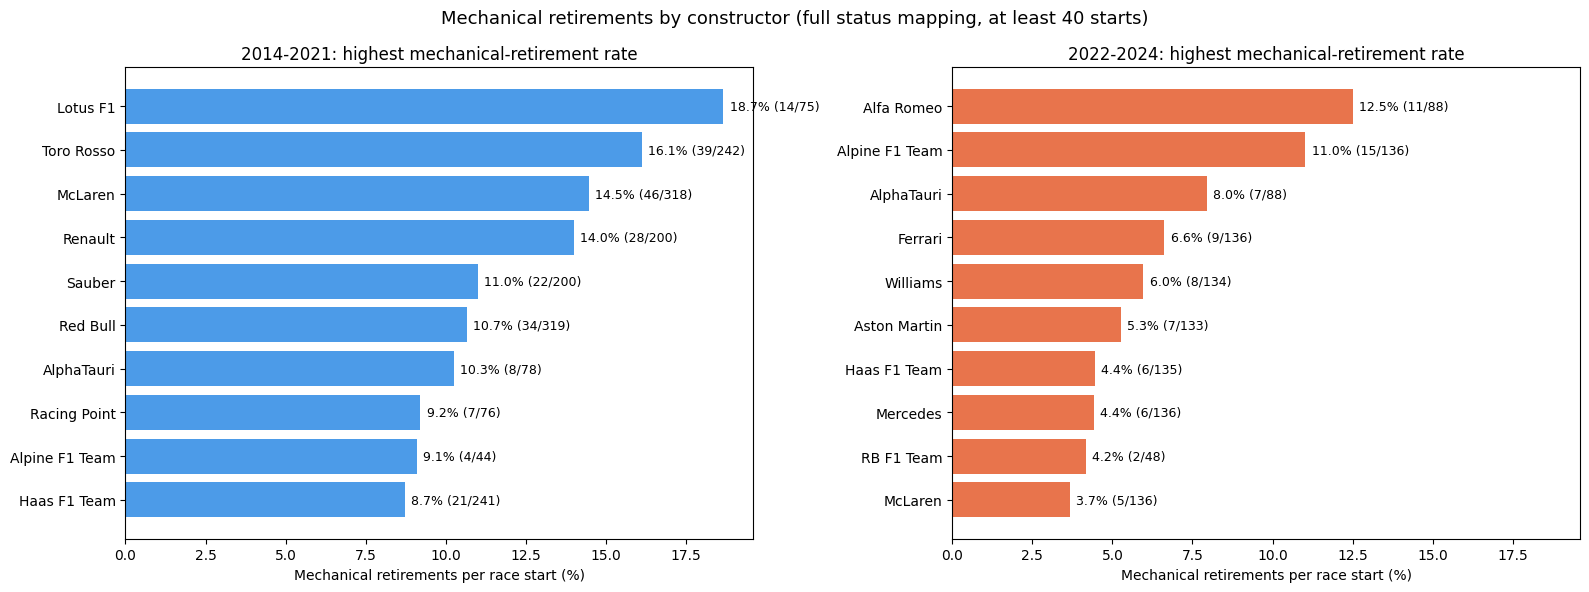

Status groups 2014-2024 (starts):
group
finished                 3825
mechanical                396
accident / driver         322
other / unknown            57
regulation / decision      12

Most common mechanical causes 2014-2024:
status
Engine        81
Brakes        49
Power Unit    42
Gearbox       42
Suspension    25
Hydraulics    15
Electrical    14
Power loss    13

2014-2021: field-wide mechanical rate 9.6%

2022-2024: field-wide mechanical rate 6.1%

Full status -> group mapping (all statuses that occur in results):
  accident / driver (12): Accident, Broken wing, Collision, Collision damage, Damage, Debris, Fatal accident, Front wing, Puncture, Spun off, Tyre, Tyre puncture
  finished (32): +1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps, +14 Laps, +15 Laps, +16 Laps, +17 Laps, +18 Laps, +19 Laps, +2 Laps, +20 Laps, +21 Laps, +22 Laps, +23 Laps, +24 Laps, +25 Laps, +26 Laps, +29 Laps, +3 Laps, +30 Laps, +4 Laps, +42 Laps, +44 Laps, +46 Laps, +5 Laps, +6 Laps, +7 Laps, +8 Laps,

2014-2021                  2022-2024                 
                  starts mechanical  rate    starts mechanical  rate
name                                                                
Lotus F1            75.0       14.0  18.7       NaN        NaN   NaN
Toro Rosso         242.0       39.0  16.1       NaN        NaN   NaN
McLaren            318.0       46.0  14.5     136.0        5.0   3.7
Renault            200.0       28.0  14.0       NaN        NaN   NaN
Sauber             200.0       22.0  11.0       NaN        NaN   NaN
Red Bull           319.0       34.0  10.7       NaN        NaN   NaN
AlphaTauri          78.0        8.0  10.3      88.0        7.0   8.0
Racing Point        76.0        7.0   9.2       NaN        NaN   NaN
Alpine F1 Team      44.0        4.0   9.1     136.0       15.0  11.0
Haas F1 Team       241.0       21.0   8.7     135.0        6.0   4.4
Alfa Romeo           NaN        NaN   NaN      88.0       11.0  12.5
Ferrari              NaN        NaN   NaN     136.0        9.0   6.6
Williams             NaN        NaN   NaN     134.0        8.0   6.0
Aston Martin         NaN        NaN   NaN     133.0        7.0   5.3
Mercedes             NaN        NaN   NaN     136.0        6.0   4.4
RB F1 Team           NaN        NaN   NaN      48.0        2.0   4.2

In [16]:
MECHANICAL = {
    'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
    'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Driveshaft', 'Fuel pressure', 'Water pressure',
    'Throttle', 'Steering', 'Technical', 'Electronics', 'Heat shield fire', 'Exhaust', 'Oil leak', 'Wheel rim',
    'Water leak', 'Fuel pump', 'Track rod', 'Oil pressure', 'Engine fire', 'Engine misfire', 'Pneumatics',
    'Rear wing', 'Fire', 'Wheel bearing', 'Fuel system', 'Oil line', 'Launch control', 'Fuel', 'Power loss',
    'Vibrations', 'Drivetrain', 'Ignition', 'Chassis', 'Battery', 'Halfshaft', 'Crankshaft', 'Alternator',
    'Oil pump', 'Fuel leak', 'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump', 'Spark plugs',
    'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger', 'Power Unit', 'ERS',
    'Brake duct', 'Cooling system', 'Wheel', 'Handling', 'Seat', 'Undertray', 'Driver Seat', 'Safety belt',
}
ACCIDENT = {
    'Accident', 'Collision', 'Spun off', 'Collision damage', 'Damage', 'Debris', 'Puncture', 'Tyre puncture',
    'Tyre', 'Broken wing', 'Front wing', 'Fatal accident',
}
REGULATION = {
    'Disqualified', 'Excluded', 'Underweight', 'Did not qualify', 'Did not prequalify', 'Withdrew',
    '107% Rule', 'Not classified', 'Safety concerns', 'Not restarted', 'Safety',
}


def status_group(status):
    if status == 'Finished' or status.startswith('+'):
        return 'finished'
    if status in MECHANICAL:
        return 'mechanical'
    if status in ACCIDENT:
        return 'accident / driver'
    if status in REGULATION:
        return 'regulation / decision'
    return 'other / unknown'


status_map = cleaned_tables['status'].assign(group=cleaned_tables['status']['status'].map(status_group))

retirements = (
    cleaned_tables['results'][['raceId', 'constructorId', 'statusId']]
    .merge(status_map, on='statusId')
    .merge(cleaned_tables['constructors'][['constructorId', 'name']], on='constructorId')
    .merge(cleaned_tables['races'][['raceId', 'year']], on='raceId')
)
retirements = retirements[~retirements['status'].isin(NON_START_STATUSES)]  # starts only


def mechanical_rates(data, start, end, min_starts=40):
    period = data[data['year'].between(start, end)]
    table = period.groupby('name').agg(
        starts=('raceId', 'size'),
        mechanical=('group', lambda g: (g == 'mechanical').sum()),
    )
    table['rate'] = table['mechanical'] / table['starts']
    return table[table['starts'] >= min_starts].sort_values('rate', ascending=False)


periods = {'2014-2021': (2014, 2021), '2022-2024': (2022, 2024)}
rates = {label: mechanical_rates(retirements, *years) for label, years in periods.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, (label, table), color in zip(axes, rates.items(), ['#4c9be8', '#e8744c']):
    top = table.head(10).sort_values('rate')
    ax.barh(top.index, top['rate'] * 100, color=color)
    for i, (rate, m, n) in enumerate(zip(top['rate'], top['mechanical'], top['starts'])):
        ax.text(rate * 100 + 0.2, i, f'{rate:.1%} ({m}/{n})', va='center', fontsize=9)
    ax.set_title(f'{label}: highest mechanical-retirement rate')
    ax.set_xlabel('Mechanical retirements per race start (%)')
fig.suptitle('Mechanical retirements by constructor (full status mapping, at least 40 starts)', fontsize=13)
fig.tight_layout()
plt.show()

modern = retirements[retirements['year'].between(2014, 2024)]
print('Status groups 2014-2024 (starts):')
print(modern['group'].value_counts().to_string())
print('\nMost common mechanical causes 2014-2024:')
print(modern.loc[modern['group'] == 'mechanical', 'status'].value_counts().head(8).to_string())
for label, table in rates.items():
    total = retirements[retirements['year'].between(*periods[label])]
    print(f'\n{label}: field-wide mechanical rate {(total["group"] == "mechanical").mean():.1%}')

print('\nFull status -> group mapping (all statuses that occur in results):')
used_statuses = status_map[status_map['statusId'].isin(cleaned_tables['results']['statusId'])]
for group, statuses in used_statuses.groupby('group')['status']:
    print(f'  {group} ({len(statuses)}): ' + ', '.join(sorted(statuses)))

pd.concat({label: table.head(10).assign(rate=lambda t: (t['rate'] * 100).round(1)) for label, table in rates.items()}, axis=1)

**Answer to Q3.**

- **2014–2021:** Lotus F1 (18.7%, 14 of 75 starts, 2014–2015 only), Toro Rosso (16.1%), McLaren (14.5%, the McLaren-Honda years) and Renault (14.0%) had the highest mechanical-retirement rates. The field-wide rate was 9.6% of starts.
- **2022–2024:** Alfa Romeo (12.5%, 11 of 88), Alpine (11.0%, 15 of 136) and AlphaTauri (8.0%) lead; the field-wide rate fell to 6.1%.
- **What changed:** reliability improved across the grid, and the ranking reshuffled. McLaren went from third-worst (14.5%) to one of the most reliable teams (3.7%). The Renault → Alpine lineage stayed near the top in both periods, and the Sauber → Alfa Romeo lineage moved from 11.0% to the highest rate. Constructor renames reset `constructorId`, so lineages appear under different names.
- With the full mapping, 396 mechanical retirements are counted in 2014–2024; counting only Engine, Gearbox and Hydraulics would have found 138 and missed causes such as Brakes (49), Power Unit (42) and Suspension (25).

*Grain:* constructor–period, built from driver–race starts. *Missingness:* the 57 starts with an unrecorded or non-car cause ("other / unknown", mostly `Retired`) are not counted as mechanical, so the rates are lower bounds. *Cutoff:* status is post-race information; it is used here only for this descriptive question and never as a model feature.

# 4. Feature Engineering & Selection

## 4.1 Leakage rules

The prediction is made **after qualifying and before the race starts**. A feature is allowed only if it is known at that moment:

| Allowed | Not allowed (post-race) |
| --- | --- |
| grid slot, qualifying position and lap time of *this* race | this race's result, points, laps, status, fastest lap |
| championship standings **before** this race (latest earlier round) | standings published after this race |
| statistics from **earlier** races (pit stops, previous season) | pit stops or lap times of this race |
| circuit, round, driver age and nationality, constructor nationality | anything computed with this race's outcome |

Every engineered feature below is built from records with a strictly earlier round (same season) or an earlier season.

## 4.2 Feature groups

| Group | Features | Why we expect it to matter |
| --- | --- | --- |
| Grid | `grid` | Starting slot; the EDA shows pole converts 63% of the time, grid 10 under 6%. |
| Qualifying | `qualifying_position`, `q1_gap_pct` | Raw pace on this weekend. `q1_gap_pct` is the Q1 time's gap to the fastest Q1 time of the same race, in %, because raw lap seconds are not comparable across circuits; it is clipped to 0–10%, since gaps above 10% come from timing errors or outliers (one Q1 time is 1,002 s) and carry no extra information. |
| Driver standings | season-to-date points and wins, previous-season points and wins | Leakage-safe **form**: how well the driver has been scoring before this race. |
| Constructor standings | the same four for the team | Car performance, the dominant factor in most eras. |
| Pit-stop history | average stop duration and stops per race, this season so far and last season | Team operational strength (only recorded from 2011). |
| Context | `round`, `alt`, `age`, `country`, `nationality_driver`, `nationality_constructor` | Circuit and season context; nationality acts as a weak proxy for team and driver identity. |

The four functions below implement the standings, pit-stop and age features. Each one uses only records from strictly earlier rounds of the same season or from the previous season, and fills "no history yet" (for example round 1) with zero.

In [17]:
def add_pre_race_driver_standings(modeling_data, driver_standings, races):
    """
    Add current-season pre-race points/wins and previous-season
    final points/wins for each driver.

    Current-season features use the latest standings record from
    an earlier round in the same season. If no earlier record
    exists, they default to zero.

    Previous-season features use the driver's final standings
    record from the immediately preceding season, or zero if
    unavailable.
    """

    race_order = races[['raceId', 'year', 'round']].copy()

    standings = (
        driver_standings[['raceId', 'driverId', 'points', 'wins']]
        .merge(
            race_order,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
    )

    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Attach each driver's standings records from the same season.
    candidates = data[
        ['_row_id', 'driverId', 'year', 'round']
    ].merge(
        standings,
        on=['driverId', 'year'],
        how='left',
        suffixes=('', '_standing')
    )

    # Only records from earlier rounds are eligible.
    candidates = candidates[
        candidates['round_standing'] < candidates['round']
    ]

    # Latest standings record before the target race.
    current_season = (
        candidates
        .sort_values(
            ['_row_id', 'round_standing', 'raceId']
        )
        .drop_duplicates('_row_id', keep='last')
        [
            ['_row_id', 'points', 'wins']
        ]
        .rename(columns={
            'points': 'driver_points_before_race',
            'wins': 'driver_wins_before_race'
        })
    )

    data = data.merge(
        current_season,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    data[
        ['driver_points_before_race', 'driver_wins_before_race']
    ] = data[
        ['driver_points_before_race', 'driver_wins_before_race']
    ].fillna(0)

    # Determine the final standings record for each driver/season.
    season_finals = (
        standings
        .sort_values(['driverId', 'year', 'round', 'raceId'])
        .drop_duplicates(['driverId', 'year'], keep='last')
        [['driverId', 'year', 'points', 'wins']]
        .rename(columns={
            'year': 'previous_season',
            'points': 'driver_previous_season_points',
            'wins': 'driver_previous_season_wins'
        })
    )

    # Match only the immediately preceding calendar season.
    data['previous_season'] = data['year'] - 1

    data = data.merge(
        season_finals,
        left_on=['driverId', 'previous_season'],
        right_on=['driverId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    data[
        ['driver_previous_season_points', 'driver_previous_season_wins']
    ] = data[
        ['driver_previous_season_points', 'driver_previous_season_wins']
    ].fillna(0)

    return data.drop(columns=['_row_id', 'previous_season'])

In [18]:
def add_pre_race_constructor_standings(
    modeling_data, constructor_standings, races
):
    """
    Add current-season pre-race points/wins and previous-season
    final points/wins for each constructor.

    Current-season features use the latest standings record from
    a strictly earlier round in the same season. If none exists,
    they default to zero.

    Previous-season features use the final standings record from
    the immediately preceding calendar season, or zero if unavailable.
    """

    race_order = races[['raceId', 'year', 'round']].copy()

    standings = (
        constructor_standings[
            ['raceId', 'constructorId', 'points', 'wins']
        ]
        .merge(
            race_order,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
        .rename(columns={
            'year': 'standing_year',
            'round': 'standing_round'
        })
    )

    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Match standings records for the same constructor and season.
    candidates = data[
        ['_row_id', 'constructorId', 'year', 'round']
    ].merge(
        standings,
        left_on=['constructorId', 'year'],
        right_on=['constructorId', 'standing_year'],
        how='left',
        validate='many_to_many'
    )

    # Only standings from strictly earlier rounds are eligible.
    candidates = candidates[
        candidates['standing_round'] < candidates['round']
    ]

    # Select the most recent eligible standings record.
    current_season = (
        candidates
        .sort_values(
            ['_row_id', 'standing_round', 'raceId']
        )
        .drop_duplicates('_row_id', keep='last')
        [
            ['_row_id', 'points', 'wins']
        ]
        .rename(columns={
            'points': 'constructor_points_before_race',
            'wins': 'constructor_wins_before_race'
        })
    )

    data = data.merge(
        current_season,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    current_cols = [
        'constructor_points_before_race',
        'constructor_wins_before_race'
    ]
    data[current_cols] = data[current_cols].fillna(0)

    # Select each constructor's final standings record per season.
    season_finals = (
        standings
        .sort_values(
            ['constructorId', 'standing_year', 'standing_round', 'raceId']
        )
        .drop_duplicates(
            ['constructorId', 'standing_year'],
            keep='last'
        )
        [
            ['constructorId', 'standing_year', 'points', 'wins']
        ]
        .rename(columns={
            'standing_year': 'previous_season',
            'points': 'constructor_previous_season_points',
            'wins': 'constructor_previous_season_wins'
        })
    )

    data['previous_season'] = data['year'] - 1

    data = data.merge(
        season_finals,
        on=['constructorId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    previous_cols = [
        'constructor_previous_season_points',
        'constructor_previous_season_wins'
    ]
    data[previous_cols] = data[previous_cols].fillna(0)

    return data.drop(columns=['_row_id', 'previous_season'])

In [19]:
def add_pit_stop_features(modeling_data, results, pit_stops, races):
    """
    Add pre-race pit-stop history features.

    Current-season features use covered races earlier in the same season.
    If no eligible earlier covered races exist, current-season metrics
    default to zero.

    Previous-season features use covered races in the previous calendar
    year. If no eligible history exists, they also default to zero.

    Pit-stop data exists only from 2011, so earlier rows get zero for all
    four features; tree models can separate them via the year-related
    standings features, and the ablation in Section 6 measures their value.

    Races without any pit-stop records are excluded from the averages.
    Within covered races, participating drivers without stop records
    are treated as having zero stops.
    """

    race_info = races[['raceId', 'year', 'round']].copy()

    # Identify races with at least one pit-stop record.
    covered_races = pit_stops['raceId'].dropna().unique()

    # Durations are already numeric seconds (Section 2.3). Stops longer than
    # 60 s are red-flag stoppages or repairs, not pit-crew performance.
    stops = pit_stops[['raceId', 'driverId', 'duration']].copy()
    stops['duration_seconds'] = pd.to_numeric(stops['duration'], errors='coerce')
    stops.loc[stops['duration_seconds'] > 60, 'duration_seconds'] = np.nan

    # Summarize each driver's stops within each race.
    race_stop_stats = (
        stops.groupby(['raceId', 'driverId'], as_index=False)
        .agg(
            stops_in_race=('raceId', 'size'),
            mean_stop_duration=('duration_seconds', 'mean')
        )
    )

    # Driver participation in covered races only.
    participation = (
        results[['raceId', 'driverId']]
        .drop_duplicates()
        .merge(
            race_info,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
    )

    participation = participation[
        participation['raceId'].isin(covered_races)
    ].copy()

    # Assume no recorded stops means zero stops within a covered race.
    participation = participation.merge(
        race_stop_stats,
        on=['raceId', 'driverId'],
        how='left',
        validate='one_to_one'
    )

    participation['stops_in_race'] = (
        participation['stops_in_race'].fillna(0)
    )

    # Preserve input row order and index-independent row identity.
    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Current-season features: only races strictly before target round.
    current_candidates = data[
        ['_row_id', 'driverId', 'year', 'round']
    ].merge(
        participation,
        on=['driverId', 'year'],
        how='left',
        suffixes=('', '_history')
    )

    current_candidates = current_candidates[
        current_candidates['round_history'].lt(
            current_candidates['round']
        )
    ]

    current_features = (
        current_candidates.groupby('_row_id')
        .agg(
            avg_stop_duration_before_race=(
                'mean_stop_duration', 'mean'
            ),
            avg_stops_per_race_before_race=(
                'stops_in_race', 'mean'
            )
        )
        .reset_index()
    )

    data = data.merge(
        current_features,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    # No eligible earlier covered races => current-season defaults of zero.
    current_cols = [
        'avg_stop_duration_before_race',
        'avg_stops_per_race_before_race'
    ]
    data[current_cols] = data[current_cols].fillna(0)

    # Previous-season features: aggregate the previous calendar year.
    previous_features = (
        participation
        .groupby(['driverId', 'year'])
        .agg(
            avg_stop_duration_previous_season=(
                'mean_stop_duration', 'mean'
            ),
            avg_stops_per_race_previous_season=(
                'stops_in_race', 'mean'
            )
        )
        .reset_index()
        .rename(columns={'year': 'previous_season'})
    )

    data['previous_season'] = data['year'] - 1

    data = data.merge(
        previous_features,
        on=['driverId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    updated_cols = [
        'avg_stop_duration_previous_season',
        'avg_stops_per_race_previous_season'
    ]
    data[updated_cols] = data[updated_cols].fillna(0)

    return data.drop(columns=['_row_id', 'previous_season'])

In [20]:
def add_driver_age(modeling_data):
    """
    Add driver age in years at the date of each target race.
    """

    data = modeling_data.copy()

    dob = pd.to_datetime(data['dob'], errors='coerce')
    race_date = pd.to_datetime(data['date'], errors='coerce')

    data['age'] = (
        (race_date - dob).dt.days / 365.2425
    )

    # Invalid dates or dates before birth are not valid ages.
    invalid_age = (data['age'] < 0) | dob.isna() | race_date.isna()
    data.loc[invalid_age, 'age'] = float('nan')
    data['age'] = np.floor(data['age'])

    return data

## 4.3 Building the driver–race modeling table

`build_modeling_table` turns driver–race entries into feature rows. The same function is used for training (all rows of the cleaned `results`) and by the inference function in Section 8, so training and inference features are computed identically. The target `podium = positionOrder <= 3` is added only for training rows.

In [21]:
def build_modeling_table(entries):
    """
    entries: one row per driver-race with raceId, driverId, constructorId, grid and,
    optionally, positionOrder (training only), qualifying_position and q1 (seconds).
    When the entries do not carry qualifying columns they are looked up in the qualifying table.
    """
    data = entries.copy()
    if 'positionOrder' not in data:
        data['positionOrder'] = np.nan

    data = (
        data
        .merge(cleaned_tables['races'][['raceId', 'circuitId', 'year', 'date', 'round']], on='raceId', how='left')
        .merge(cleaned_tables['circuits'][['circuitId', 'country', 'alt']], on='circuitId', how='left')
    )

    qualifying_columns = ['q1', 'q2', 'q3', 'qualifying_position']
    if not any(column in entries.columns for column in qualifying_columns):
        qualifying = cleaned_tables['qualifying'][['raceId', 'driverId', 'q1', 'q2', 'q3', 'position']]
        data = data.merge(qualifying.rename(columns={'position': 'qualifying_position'}),
                          on=['raceId', 'driverId'], how='left')
    for column in qualifying_columns:
        if column not in data:
            data[column] = np.nan

    # Qualifying pace relative to the fastest Q1 time of the same race (known once qualifying ends)
    pole_q1 = cleaned_tables['qualifying'].groupby('raceId')['q1'].min().rename('pole_q1')
    data = data.merge(pole_q1, on='raceId', how='left')
    data['q1_gap_pct'] = ((data['q1'] / data['pole_q1'] - 1) * 100).clip(lower=0, upper=10)

    data = (
        data
        .merge(cleaned_tables['drivers'][['driverId', 'dob', 'nationality']], on='driverId', how='left')
        .merge(cleaned_tables['constructors'][['constructorId', 'nationality']], on='constructorId',
               how='left', suffixes=('_driver', '_constructor'))
    )
    data = add_pre_race_driver_standings(data, cleaned_tables['driver_standings'], cleaned_tables['races'])
    data = add_pre_race_constructor_standings(data, cleaned_tables['constructor_standings'], cleaned_tables['races'])
    data = add_driver_age(data)
    data = add_pit_stop_features(data, cleaned_tables['results'], cleaned_tables['pit_stops'], cleaned_tables['races'])

    # Before 1994 there is no qualifying table: the grid slot is the best available proxy
    data['qualifying_position'] = data['qualifying_position'].fillna(data['grid'])
    data['podium'] = (data['positionOrder'] <= 3).astype(int)
    return data.drop(columns=['circuitId', 'dob', 'date', 'pole_q1'])


modeling_data = build_modeling_table(
    cleaned_tables['results'][['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder']]
)
assert not modeling_data.duplicated(['raceId', 'driverId']).any()
print(modeling_data.shape)
modeling_data.isna().mean().loc[lambda s: s > 0].round(3).rename('share missing')

(26534, 30)


q1            0.610
q2            0.780
q3            0.863
q1_gap_pct    0.610
Name: share missing, dtype: float64

## 4.4 Handling qualifying-coverage drift: three table variants

Qualifying lap times exist for 39% of all entries (from 1994, complete only from 2003). We keep three variants and let the experiments decide:

| Variant | Rows | Qualifying lap-time feature | Used for |
| --- | --- | --- | --- |
| `modeling_data` | all seasons | `q1_gap_pct` with 61% missing | preprocessing-order experiment (imputation matters here) |
| `dropped_qual_time_columns` | all seasons | dropped | model comparison (all-years table) |
| `dropped_qual_time_rows` | only entries with a Q1 time (1994+) | kept | model comparison and **final models** |

The final models use `dropped_qual_time_rows`: it keeps the qualifying-pace signal, its training data (1994–2019) is closer to the test era, and Section 5 shows it scores at least as well as the all-years table.

In [22]:
dropped_qual_time_columns = modeling_data.drop(columns=['q1', 'q2', 'q3', 'q1_gap_pct'])
dropped_qual_time_rows = modeling_data[modeling_data['q1'].notna()].drop(columns=['q2', 'q3'])

pd.DataFrame({
    'rows': [len(modeling_data), len(dropped_qual_time_columns), len(dropped_qual_time_rows)],
    'first season': [modeling_data['year'].min(), dropped_qual_time_columns['year'].min(), dropped_qual_time_rows['year'].min()],
    'podium rate': [modeling_data['podium'].mean(), dropped_qual_time_columns['podium'].mean(), dropped_qual_time_rows['podium'].mean()],
}, index=['modeling_data', 'dropped_qual_time_columns', 'dropped_qual_time_rows']).round(3)

,rows,first season,podium rate
modeling_data,26534,1950,0.127
dropped_qual_time_columns,26534,1950,0.127
dropped_qual_time_rows,10338,1994,0.142


## 4.5 Feature lists

Feature lists are explicit and checked: `select_features` raises an error if a listed column is not in the table, so a typo can no longer silently drop a feature. Identifiers (`raceId`, `driverId`, `constructorId`), `year`, the target and `positionOrder` are never features.

In [23]:
FEATURE_GROUPS = {
    'grid': ['grid'],
    'qualifying': ['qualifying_position', 'q1_gap_pct'],
    'driver standings': [
        'driver_points_before_race', 'driver_wins_before_race',
        'driver_previous_season_points', 'driver_previous_season_wins',
    ],
    'constructor standings': [
        'constructor_points_before_race', 'constructor_wins_before_race',
        'constructor_previous_season_points', 'constructor_previous_season_wins',
    ],
    'pit-stop history': [
        'avg_stop_duration_before_race', 'avg_stops_per_race_before_race',
        'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season',
    ],
    'context': ['round', 'alt', 'age', 'country', 'nationality_driver', 'nationality_constructor'],
}
CATEGORICAL = {'country', 'nationality_driver', 'nationality_constructor'}

all_features = [f for group in FEATURE_GROUPS.values() for f in group]
numeric_cols = [f for f in all_features if f not in CATEGORICAL]
categorical_cols = [f for f in all_features if f in CATEGORICAL]
numeric_cols_all_years = [f for f in numeric_cols if f != 'q1_gap_pct']

FORBIDDEN = {'positionOrder', 'podium', 'year', 'raceId', 'driverId', 'constructorId'}


def select_features(data, numeric, categorical):
    """Return the two lists after checking every column exists and none is forbidden."""
    listed = list(numeric) + list(categorical)
    missing = [c for c in listed if c not in data.columns]
    if missing:
        raise KeyError(f'Feature columns not in the table: {missing}')
    forbidden = FORBIDDEN.intersection(listed)
    if forbidden:
        raise ValueError(f'Leaky or identifier columns listed as features: {sorted(forbidden)}')
    if len(set(listed)) != len(listed):
        raise ValueError('Duplicate feature names')
    return list(numeric), list(categorical)


datasets = [
    (dropped_qual_time_columns, numeric_cols_all_years, categorical_cols, 'All years (no Q1 time)'),
    (dropped_qual_time_rows, numeric_cols, categorical_cols, 'Qualifying era (rows with Q1 time)'),
]
for data, num, cat, title in datasets:
    select_features(data, num, cat)
    print(f'{title}: {len(num)} numeric + {len(cat)} categorical features')

All years (no Q1 time): 17 numeric + 3 categorical features
Qualifying era (rows with Q1 time): 18 numeric + 3 categorical features


## 4.6 Train / validation / test split

| Split | Seasons | Purpose |
| --- | --- | --- |
| Training | up to 2019 | fit models and preprocessing |
| Validation | 2020–2021 | choose hyperparameters, decision threshold and early-stopping epoch |
| Test | 2022–2024 | reported once, never used for any choice |

**Why chronological, not random.** The model will be used on future races, so it must be judged on seasons it has never seen. A random split would put races from the same season in training and test: standings features and team form are strongly correlated within a season, which would make test scores look better than they are in practice. The test seasons also start a new technical era (2022 ground-effect rules), so the test score is an honest check of how well the model transfers to new regulations.

In [24]:
def split_by_season(data):
    training = data[data['year'] <= 2019]
    validation = data[data['year'].between(2020, 2021)]
    testing = data[data['year'] >= 2022]
    return training, validation, testing


split_summary = []
for data, num, cat, title in datasets:
    for name, part in zip(['train', 'validation', 'test'], split_by_season(data)):
        split_summary.append({'table': title, 'split': name, 'rows': len(part),
                              'seasons': f"{part['year'].min()}-{part['year'].max()}",
                              'podium rate': round(part['podium'].mean(), 3)})
pd.DataFrame(split_summary)

,table,split,rows,seasons,podium rate
0,All years (no Q1 time),train,24395,1950-2019,0.125
1,All years (no Q1 time),validation,780,2020-2021,0.150
2,All years (no Q1 time),test,1359,2022-2024,0.150
3,Qualifying era (rows with Q1 time),train,8221,1994-2019,0.140
4,Qualifying era (rows with Q1 time),validation,771,2020-2021,0.150
5,Qualifying era (rows with Q1 time),test,1346,2022-2024,0.152


## 4.7 Evidence for each feature

Computed on the **training seasons of the qualifying-era table only**, so no validation or test information shapes the feature choice. For each numeric feature we report how well it ranks podium finishers on its own (univariate ROC-AUC, 0.5 = no signal) and plot the podium rate across its deciles.

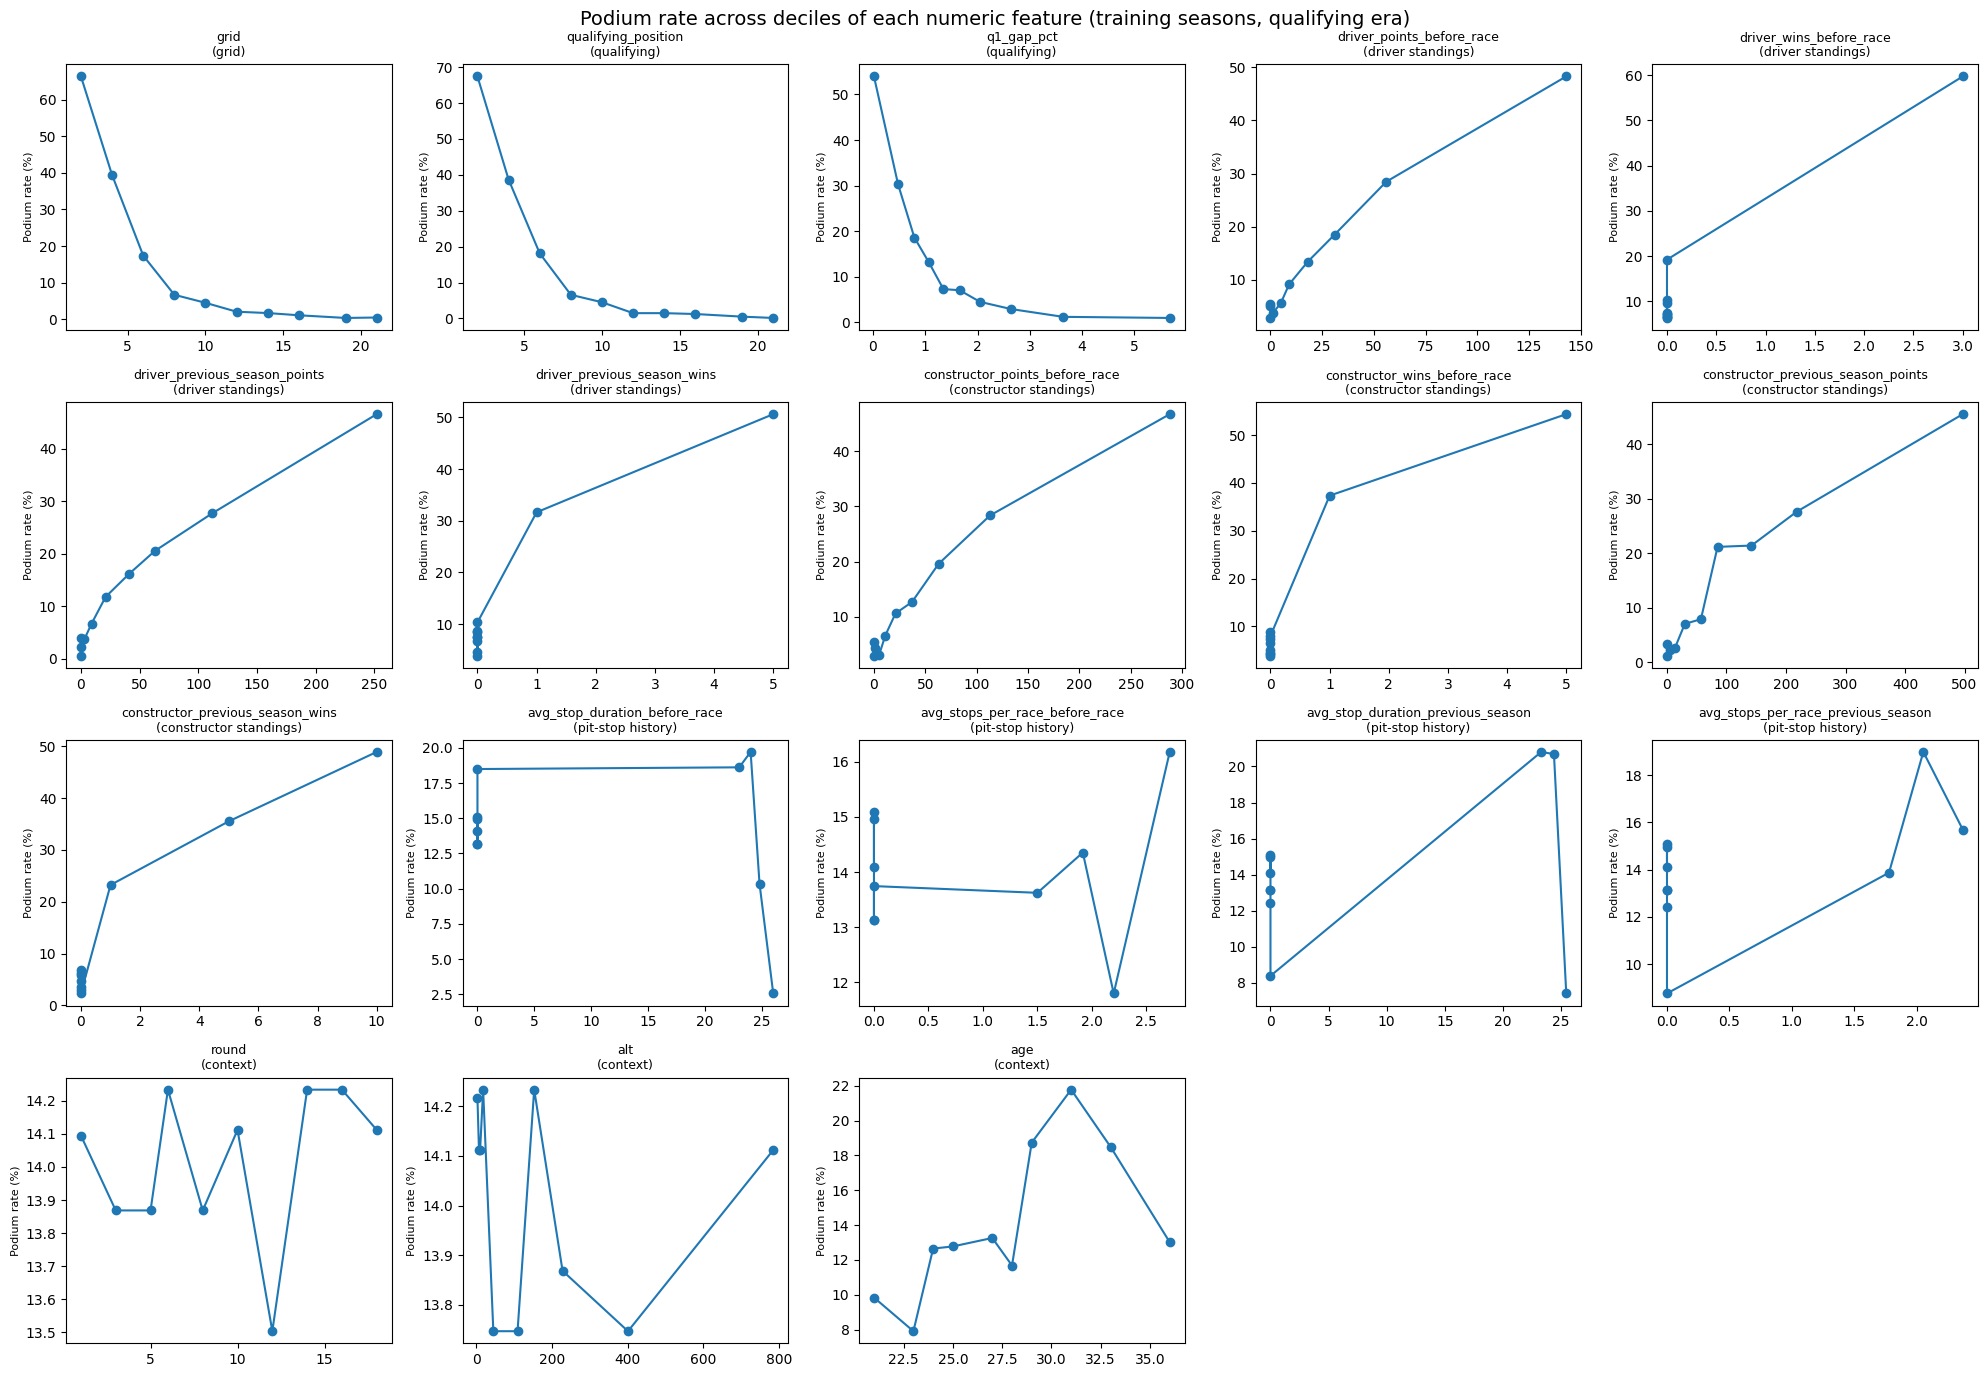

Podium rate by constructor nationality (>= 200 entries):
nationality_constructor
German      39.5
Austrian    30.0
Italian     21.0
British     12.6
French      10.2
Irish        4.8
Japanese     4.0
Indian       1.4
Swiss        1.3


,feature,group,univariate ROC-AUC,direction,Spearman with podium,missing share
1,qualifying_position,qualifying,0.909,lower -> more podiums,-0.492,0.0
0,grid,grid,0.904,lower -> more podiums,-0.487,0.0
2,q1_gap_pct,qualifying,0.831,lower -> more podiums,-0.397,0.0
9,constructor_previous_season_points,constructor standings,0.803,higher -> more podiums,0.366,0.0
5,driver_previous_season_points,driver standings,0.802,higher -> more podiums,0.368,0.0
10,constructor_previous_season_wins,constructor standings,0.796,higher -> more podiums,0.441,0.0
8,constructor_wins_before_race,constructor standings,0.788,higher -> more podiums,0.480,0.0
3,driver_points_before_race,driver standings,0.783,higher -> more podiums,0.346,0.0
7,constructor_points_before_race,constructor standings,0.779,higher -> more podiums,0.338,0.0
6,driver_previous_season_wins,driver standings,0.748,higher -> more podiums,0.415,0.0


In [25]:
evidence_train, _, _ = split_by_season(dropped_qual_time_rows)
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}

rows = []
for feature in numeric_cols + ['q1']:
    values = evidence_train[feature]
    auc = roc_auc_score(evidence_train['podium'], values.fillna(values.median()))
    rows.append({
        'feature': feature,
        'group': group_of.get(feature, 'raw lap time (not used)'),
        'univariate ROC-AUC': round(max(auc, 1 - auc), 3),
        'direction': 'higher -> more podiums' if auc >= 0.5 else 'lower -> more podiums',
        'Spearman with podium': round(values.corr(evidence_train['podium'], method='spearman'), 3),
        'missing share': round(values.isna().mean(), 3),
    })
feature_evidence = pd.DataFrame(rows).sort_values('univariate ROC-AUC', ascending=False)

fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax, feature in zip(axes.flat, numeric_cols):
    values = evidence_train[feature]
    bins = pd.qcut(values.rank(method='first'), q=min(10, values.nunique()), labels=False)
    rate = evidence_train.groupby(bins)['podium'].mean()
    centers = values.groupby(bins).median()
    ax.plot(centers, rate * 100, marker='o')
    ax.set_title(f'{feature}\n({group_of[feature]})', fontsize=9)
    ax.set_ylabel('Podium rate (%)', fontsize=8)
for ax in axes.flat[len(numeric_cols):]:
    ax.axis('off')
fig.suptitle('Podium rate across deciles of each numeric feature (training seasons, qualifying era)', fontsize=14)
fig.tight_layout()
plt.show()

nat_rate = (
    evidence_train.groupby('nationality_constructor')['podium'].agg(['mean', 'size'])
    .query('size >= 200').sort_values('mean', ascending=False)
)
print('Podium rate by constructor nationality (>= 200 entries):')
print((nat_rate['mean'] * 100).round(1).to_string())
feature_evidence

**What the evidence says about each group**

- **Grid and qualifying are the strongest signals.** `qualifying_position` (ROC-AUC 0.909) and `grid` (0.904) on their own rank podium finishers very well, and the podium rate falls steeply over their first deciles.
- **The qualifying-time transformation is justified empirically.** Raw `q1` seconds have almost no signal (ROC-AUC 0.536) because lap times depend on the circuit; the same information as a gap to the fastest Q1 time of the race (`q1_gap_pct`) reaches 0.831.
- **Standings are the leakage-safe form features.** All eight driver and constructor standings features score 0.74–0.80 and rise monotonically with the podium rate. They are computed only from earlier rounds or the previous season.
- **Pit-stop history and context are weak on their own** (0.50–0.57). Pit-stop history is zero before 2011, which flattens its signal. We keep these groups for now and let the ablation in Section 6 measure whether they help in combination with the others; `age` shows a mild peak around 30.
- **Constructor nationality** separates teams with very different podium rates (printed above), which is why it is kept as a categorical feature despite being only a proxy for team identity.

## 4.8 Preprocessing and its effect on the data

Inside every model the same preprocessing is applied, **fitted on the training seasons only**:

- **Numeric:** median imputation, then standardization (mean 0, standard deviation 1) for logistic regression and the neural network. The random forest uses the imputed values without scaling, because trees split on thresholds and are unaffected by monotone rescaling.
- **Categorical:** most-frequent imputation, then one-hot encoding with `handle_unknown='ignore'`, so a nationality first seen in the test seasons does not crash the model.

The plots show what this does to three features of the all-seasons table, where imputation actually matters.

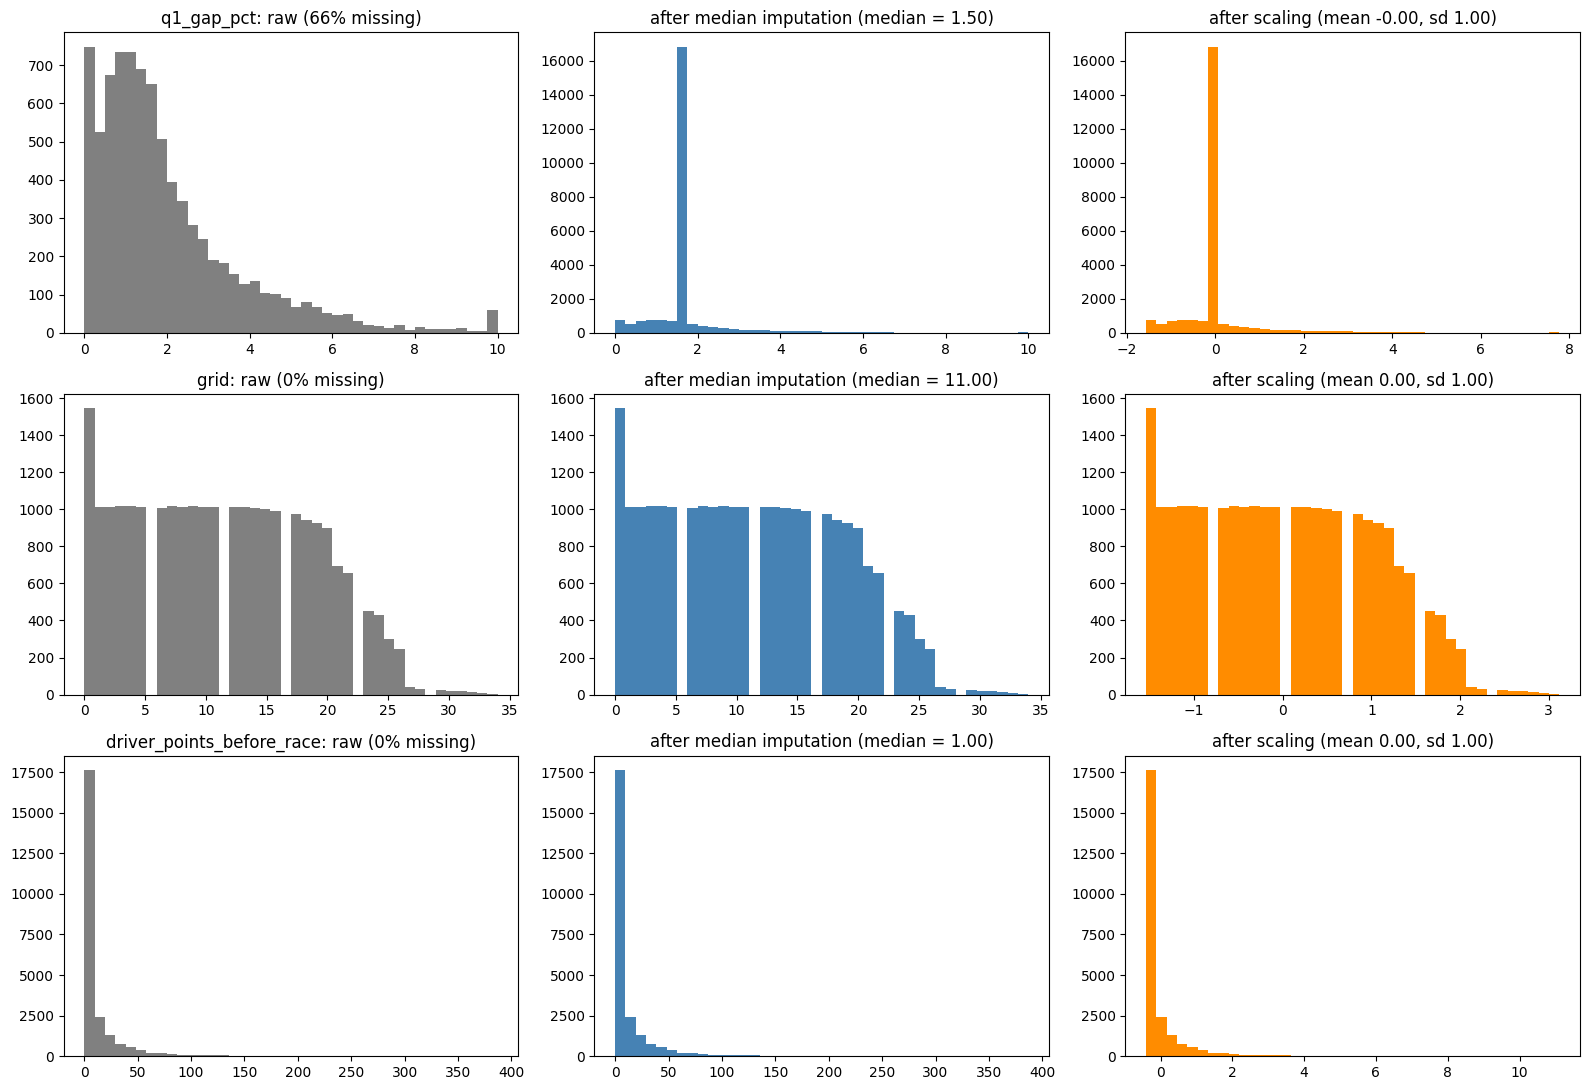

One-hot encoding expands 3 categorical columns into 97 binary columns on the all-seasons training data
Median imputation puts 66% of q1_gap_pct values on a single spike at 1.50%, which is why the qualifying-era table (no imputation needed) is preferred.


In [26]:
effect_train, _, _ = split_by_season(modeling_data)
effect_features = ['q1_gap_pct', 'grid', 'driver_points_before_race']

imputer = SimpleImputer(strategy='median').fit(effect_train[effect_features])
imputed = pd.DataFrame(imputer.transform(effect_train[effect_features]), columns=effect_features)
scaler = StandardScaler().fit(imputed)
scaled = pd.DataFrame(scaler.transform(imputed), columns=effect_features)

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for row, feature in enumerate(effect_features):
    raw = effect_train[feature]
    axes[row, 0].hist(raw.dropna(), bins=40, color='grey')
    axes[row, 0].set_title(f'{feature}: raw ({raw.isna().mean():.0%} missing)')
    axes[row, 1].hist(imputed[feature], bins=40, color='steelblue')
    axes[row, 1].set_title(f'after median imputation (median = {imputer.statistics_[row]:.2f})')
    axes[row, 2].hist(scaled[feature], bins=40, color='darkorange')
    axes[row, 2].set_title(f'after scaling (mean {scaled[feature].mean():.2f}, sd {scaled[feature].std():.2f})')
fig.tight_layout()
plt.show()

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(effect_train[categorical_cols].fillna('missing'))
print('One-hot encoding expands', len(categorical_cols), 'categorical columns into',
      sum(len(c) for c in encoder.categories_), 'binary columns on the all-seasons training data')
print(f'Median imputation puts {effect_train["q1_gap_pct"].isna().mean():.0%} of q1_gap_pct values on a single spike '
      f'at {imputer.statistics_[0]:.2f}%, which is why the qualifying-era table (no imputation needed) is preferred.')

# 5. Predictive Modeling

## 5.1 Metrics and protocol

**Primary metric: PR-AUC** (average precision). Podiums are about 15% of rows in the modern era, and PR-AUC measures how well true podium finishers are ranked above everyone else without being inflated by the many easy negatives. **Secondary metric: ROC-AUC**, the overall separation of the two classes, which is easy to compare with other work. **F1** (with precision and recall) describes the yes/no decisions at the chosen threshold. Accuracy is shown for completeness but is not used for any decision: predicting "no podium" for everyone already scores about 85%.

**Protocol, identical for every model:**

1. Fit preprocessing and the model on the **training** seasons.
2. Choose hyperparameters by **validation PR-AUC** (the primary metric).
3. Choose the decision threshold that maximizes **validation F1**.
4. Report training, validation and **test** scores. The test set is scored once at the end and influences nothing.

All three models use the same rows and the same feature list for a given table, so their scores are directly comparable.

In [27]:
def make_preprocessor(numeric, categorical, scale=True):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scaler', StandardScaler()))
    transformers = []
    if numeric:
        transformers.append(('numerical', Pipeline(numeric_steps), numeric))
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical))
    return ColumnTransformer(transformers)


def prepare_splits(data, numeric, categorical, scale=True):
    """Fit preprocessing on the training seasons only and transform all three splits."""
    numeric, categorical = select_features(data, numeric, categorical)
    features = numeric + categorical
    parts = dict(zip(['train', 'val', 'test'], split_by_season(data)))
    preprocessor = make_preprocessor(numeric, categorical, scale=scale)
    X = {'train': preprocessor.fit_transform(parts['train'][features])}
    X['val'] = preprocessor.transform(parts['val'][features])
    X['test'] = preprocessor.transform(parts['test'][features])
    y = {name: part['podium'].to_numpy() for name, part in parts.items()}
    return preprocessor, X, y, features


def best_f1_threshold(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best = int(np.argmax(f1))
    return float(thresholds[best]), float(f1[best])


def evaluate(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {
        'PR-AUC': average_precision_score(y_true, prob),
        'ROC-AUC': roc_auc_score(y_true, prob),
        'F1': f1_score(y_true, pred, zero_division=0),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'Accuracy': accuracy_score(y_true, pred),
    }


def score_splits(predict_proba, X, y, threshold):
    return pd.DataFrame({split: evaluate(y[split], predict_proba(X[split]), threshold) for split in ['train', 'val', 'test']}).T


def plot_split_metrics(metrics, title, ax):
    shown = metrics[['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall']]
    shown.T.plot(kind='bar', ax=ax, color=['#bbbbbb', '#4c9be8', '#e8744c'], width=0.8)
    ax.set_ylim(0, 1.2)
    ax.set_title(title, fontsize=10)
    ax.legend(['train', 'validation', 'test'], fontsize=8, loc='upper center', ncol=3)
    ax.tick_params(axis='x', rotation=0)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontsize=7, padding=1)


model_results = {}

## 5.2 Baseline: rank drivers by grid position

The simplest reasonable predictor needs no training at all: **the better the grid slot, the more likely a podium**. Its score is `-grid` (grid 0, a pit-lane start or non-start, counts as the back of the grid), and its yes/no rule "podium if grid ≤ k" uses the k that maximizes validation F1. Every model below must beat this to earn its complexity. Logistic regression then serves as the **statistical-model baseline** for the random forest and the neural network.

In [28]:
def train_grid_baseline(data, title):
    parts = dict(zip(['train', 'val', 'test'], split_by_season(data)))
    score = {name: -part['grid'].replace(0, 30).to_numpy(dtype=float) for name, part in parts.items()}
    y = {name: part['podium'].to_numpy() for name, part in parts.items()}
    threshold, _ = best_f1_threshold(y['val'], score['val'])
    metrics = pd.DataFrame({split: evaluate(y[split], score[split], threshold) for split in ['train', 'val', 'test']}).T
    return {'name': 'Grid baseline', 'dataset': title, 'metrics': metrics,
            'threshold': threshold, 'params': {'predict podium if grid <=': int(-threshold)}}


for data, num, cat, title in datasets:
    model_results[(title, 'Grid baseline')] = train_grid_baseline(data, title)
    print(title, '| rule: podium if grid <=', int(-model_results[(title, 'Grid baseline')]['threshold']))
    display(model_results[(title, 'Grid baseline')]['metrics'].round(3))

All years (no Q1 time) | rule: podium if grid <= 3


,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy
train,0.495,0.890,0.542,0.543,0.541,0.886
val,0.639,0.909,0.692,0.692,0.692,0.908
test,0.647,0.914,0.649,0.650,0.647,0.895


Qualifying era (rows with Q1 time) | rule: podium if grid <= 3


,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy
train,0.602,0.908,0.631,0.629,0.632,0.896
val,0.643,0.916,0.695,0.692,0.698,0.908
test,0.647,0.913,0.649,0.650,0.647,0.894


## 5.3 Logistic regression

**How it works.** Logistic regression models the log-odds of a podium as a weighted sum of the (standardized) features and turns it into a probability with the sigmoid function. Weights are fitted by maximizing the likelihood with an L2 penalty whose strength is `1/C`.

**Search.** `C` ∈ {0.1, 1, 10} × class weighting ∈ {none, balanced}: 6 candidates, chosen by validation PR-AUC.

**Limitations.** It can only draw a linear boundary in feature space, so interactions (for example, "front row *and* a top team") and the strongly non-linear grid effect must be approximated by the weights; correlated standings features share credit unpredictably; and with balanced class weights its probabilities are shifted upward and are no longer calibrated.

All years (no Q1 time)


,C,class_weight,val PR-AUC
0,0.1,None,0.7046
1,0.1,balanced,0.7002
2,1.0,None,0.7019
3,1.0,balanced,0.6962
4,10.0,None,0.6986
5,10.0,balanced,0.6933


Qualifying era (rows with Q1 time)


,C,class_weight,val PR-AUC
0,0.1,None,0.7251
1,0.1,balanced,0.7199
2,1.0,None,0.7188
3,1.0,balanced,0.7002
4,10.0,None,0.7086
5,10.0,balanced,0.6895


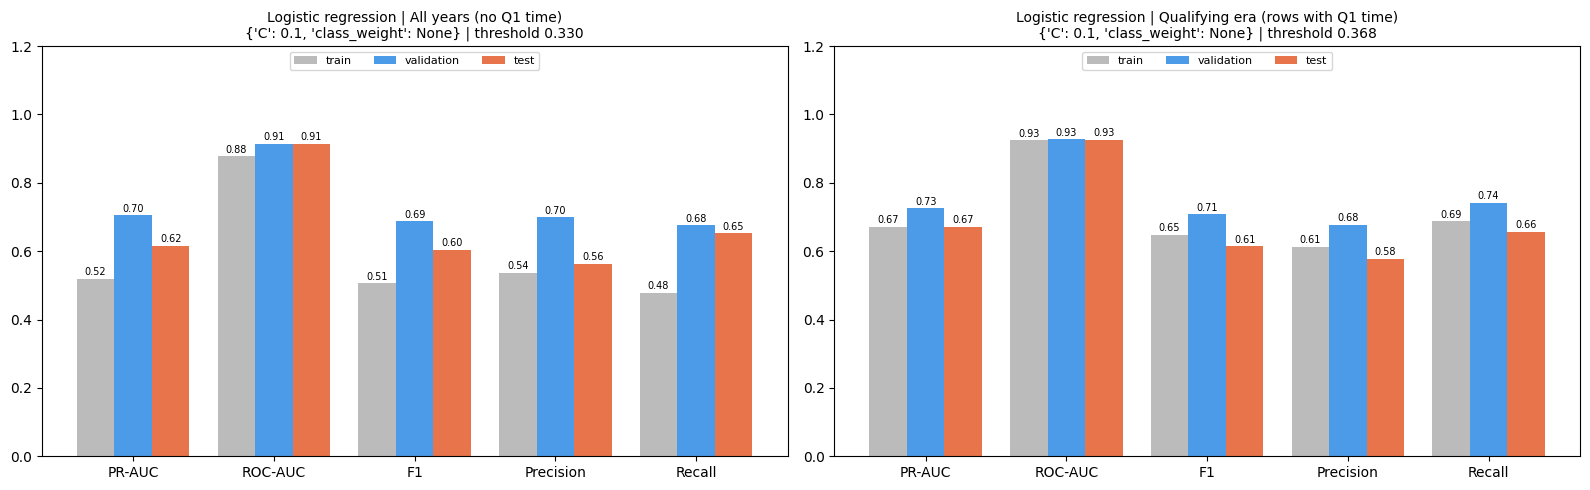

In [29]:
def train_logistic_regression_model(data, numeric, categorical, title):
    preprocessor, X, y, features = prepare_splits(data, numeric, categorical, scale=True)
    search = []
    best = None
    for C in [0.1, 1.0, 10.0]:
        for class_weight in [None, 'balanced']:
            model = LogisticRegression(C=C, class_weight=class_weight, max_iter=2000)
            model.fit(X['train'], y['train'])
            val_pr_auc = average_precision_score(y['val'], model.predict_proba(X['val'])[:, 1])
            search.append({'C': C, 'class_weight': str(class_weight), 'val PR-AUC': val_pr_auc})
            if best is None or val_pr_auc > best[0]:
                best = (val_pr_auc, model, {'C': C, 'class_weight': class_weight})
    _, model, params = best
    predict = lambda X_: model.predict_proba(X_)[:, 1]
    threshold, _ = best_f1_threshold(y['val'], predict(X['val']))
    return {
        'name': 'Logistic regression', 'dataset': title, 'model': model, 'preprocessor': preprocessor,
        'features': features, 'params': params, 'threshold': threshold, 'predict': predict,
        'metrics': score_splits(predict, X, y, threshold), 'search': pd.DataFrame(search),
    }


fig, axes = plt.subplots(1, len(datasets), figsize=(8 * len(datasets), 5))
for ax, (data, num, cat, title) in zip(np.atleast_1d(axes), datasets):
    result = train_logistic_regression_model(data, num, cat, title)
    model_results[(title, 'Logistic regression')] = result
    plot_split_metrics(result['metrics'], f"Logistic regression | {title}\n{result['params']} | threshold {result['threshold']:.3f}", ax)
    print(title)
    display(result['search'].round(4))
fig.tight_layout()
plt.show()

## 5.4 Random forest

**How it works.** A random forest trains many decision trees, each on a bootstrap sample of the rows and with a random subset of features considered at every split, and averages their predicted probabilities. Trees capture non-linear effects and interactions directly (for example, the sharp drop in podium rate after grid 3), and averaging many decorrelated trees reduces variance.

**Search.** 4 settings of tree count, maximum depth and minimum leaf size, all with balanced class weights; chosen by validation PR-AUC. Numeric features are imputed but not scaled.

**Limitations.** Probabilities are averaged votes, not calibrated likelihoods; it cannot extrapolate beyond values seen in training (a problem when points systems change, as in 2010); one-hot nationality columns with few podiums are rarely chosen for splits; and impurity-based importance is biased, which is why Section 7 uses permutation importance and SHAP instead.

All years (no Q1 time)


,n_estimators,max_depth,min_samples_leaf,val PR-AUC
0,200,8,1,0.6802
1,200,12,1,0.6913
2,300,8,3,0.6899
3,300,12,3,0.6978


Qualifying era (rows with Q1 time)


,n_estimators,max_depth,min_samples_leaf,val PR-AUC
0,200,8,1,0.6830
1,200,12,1,0.6813
2,300,8,3,0.6939
3,300,12,3,0.6960


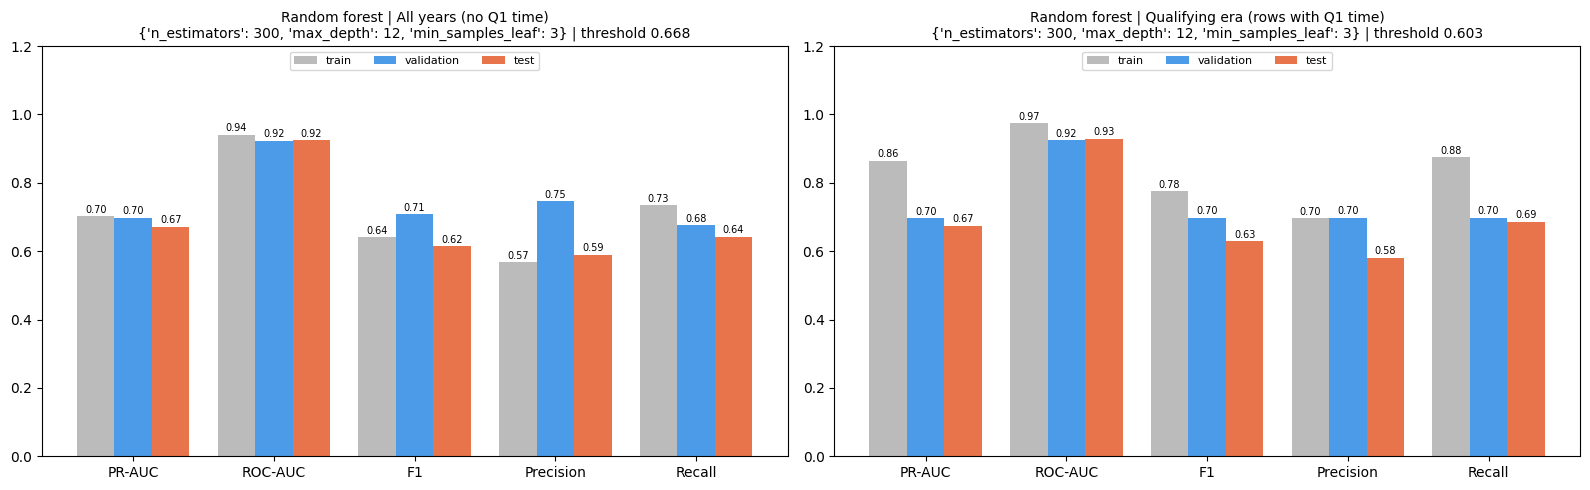

In [30]:
RF_PARAMS = [
    {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 1},
    {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 1},
    {'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 3},
    {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 3},
]


def train_random_forest_model(data, numeric, categorical, title):
    preprocessor, X, y, features = prepare_splits(data, numeric, categorical, scale=False)
    search = []
    best = None
    for params in RF_PARAMS:
        model = RandomForestClassifier(**params, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
        model.fit(X['train'], y['train'])
        val_pr_auc = average_precision_score(y['val'], model.predict_proba(X['val'])[:, 1])
        search.append({**params, 'val PR-AUC': val_pr_auc})
        if best is None or val_pr_auc > best[0]:
            best = (val_pr_auc, model, params)
    _, model, params = best
    predict = lambda X_: model.predict_proba(X_)[:, 1]
    threshold, _ = best_f1_threshold(y['val'], predict(X['val']))
    return {
        'name': 'Random forest', 'dataset': title, 'model': model, 'preprocessor': preprocessor,
        'features': features, 'params': params, 'threshold': threshold, 'predict': predict,
        'metrics': score_splits(predict, X, y, threshold), 'search': pd.DataFrame(search),
    }


fig, axes = plt.subplots(1, len(datasets), figsize=(8 * len(datasets), 5))
for ax, (data, num, cat, title) in zip(np.atleast_1d(axes), datasets):
    result = train_random_forest_model(data, num, cat, title)
    model_results[(title, 'Random forest')] = result
    plot_split_metrics(result['metrics'], f"Random forest | {title}\n{result['params']} | threshold {result['threshold']:.3f}", ax)
    print(title)
    display(result['search'].round(4))
fig.tight_layout()
plt.show()

## 5.5 Shallow neural network

**How it works.** A feed-forward network with **two hidden layers** (ReLU activations, dropout after each) and a sigmoid output unit. It learns non-linear combinations of the standardized features by minimizing binary cross-entropy with the AdamW optimizer (Adam with decoupled weight decay). Class weights make each podium count as much as the more numerous non-podiums. Early stopping watches the validation loss and restores the weights of the best epoch (patience 10).

**Search.** 3 configurations of layer sizes, learning rate, weight decay and dropout; chosen by validation PR-AUC.

**Limitations.** It needs scaled inputs and more data than the linear model to be stable; results vary slightly with the random seed; class weighting shifts the predicted probabilities upward, so they are scores rather than calibrated probabilities (which is why the tuned threshold is well above 0.5); and the model is not directly interpretable, hence Section 7.

**Reading the loss curves.** The training loss includes the class weights and dropout while the validation loss does not, so the two curves are not on the same scale. What matters is the validation curve and the dashed line marking the restored epoch.

2026-10-15 19:20:08.799259: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


All years (no Q1 time)


,hidden_layers,learning_rate,weight_decay,dropout,epochs run,best epoch,val PR-AUC
0,"(64, 32)",0.0010,0.0001,0.1,19,8,0.7255
1,"(32, 16)",0.0010,0.0010,0.2,12,1,0.7205
2,"(128, 64)",0.0003,0.0001,0.1,30,19,0.7048


Qualifying era (rows with Q1 time)


,hidden_layers,learning_rate,weight_decay,dropout,epochs run,best epoch,val PR-AUC
0,"(64, 32)",0.0010,0.0001,0.1,18,7,0.7208
1,"(32, 16)",0.0010,0.0010,0.2,12,1,0.7081
2,"(128, 64)",0.0003,0.0001,0.1,26,15,0.6971


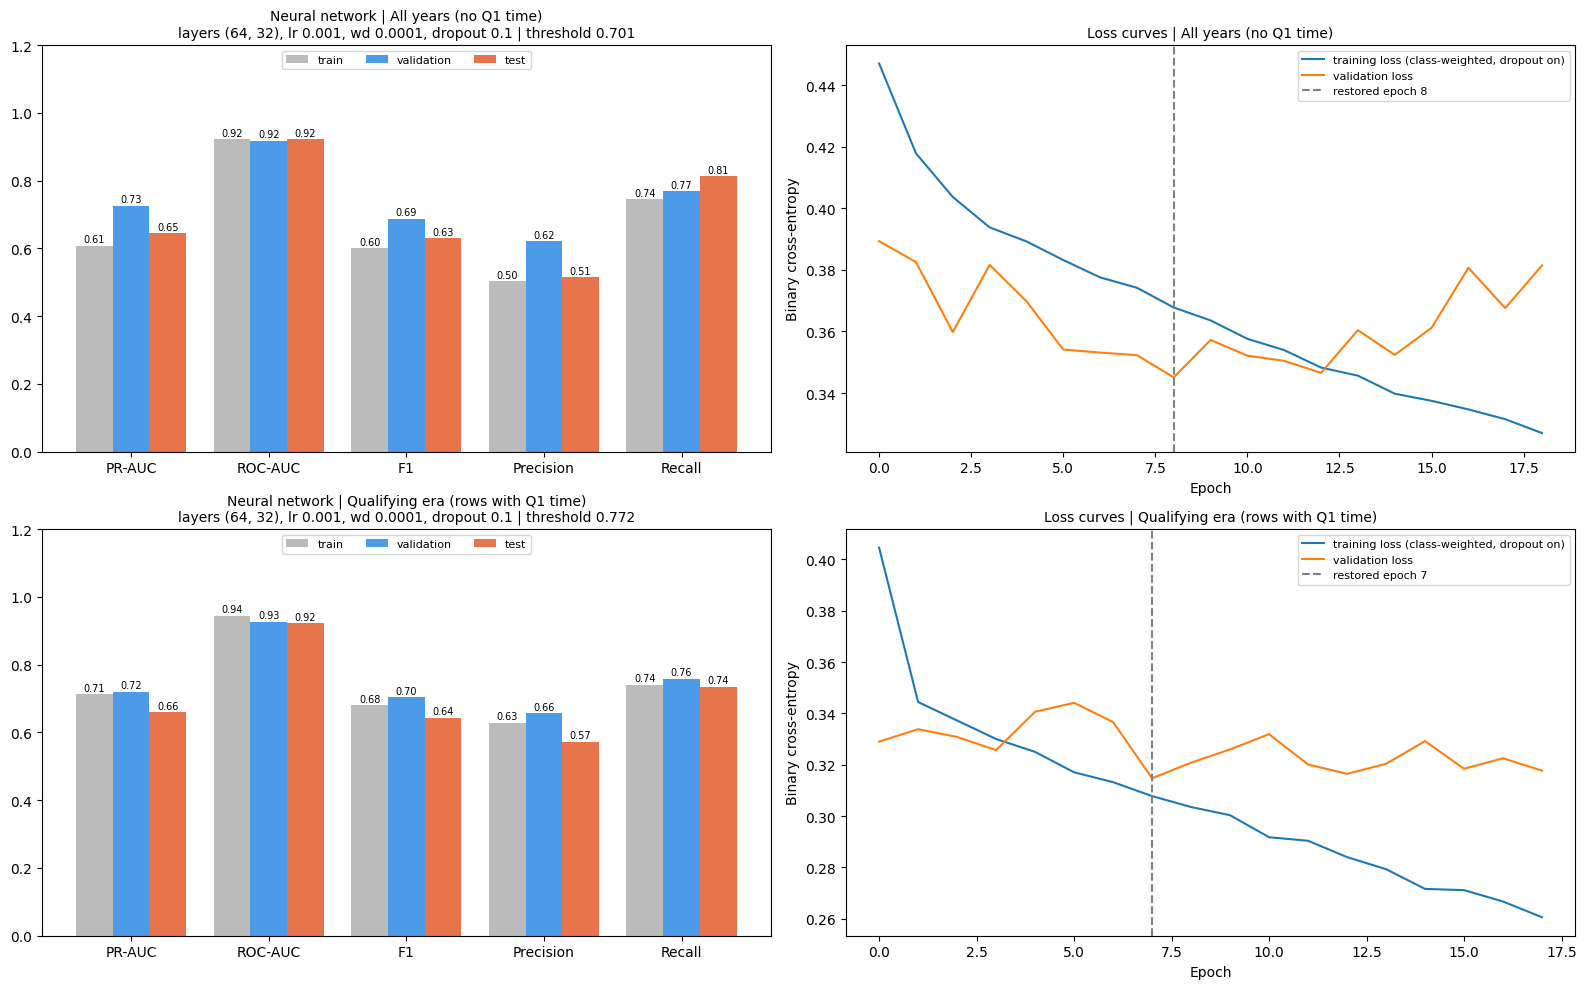

In [31]:
NN_PARAMS = [
    {'hidden_layers': (64, 32), 'learning_rate': 0.001, 'weight_decay': 0.0001, 'dropout': 0.1},
    {'hidden_layers': (32, 16), 'learning_rate': 0.001, 'weight_decay': 0.001, 'dropout': 0.2},
    {'hidden_layers': (128, 64), 'learning_rate': 0.0003, 'weight_decay': 0.0001, 'dropout': 0.1},
]


def build_network(n_inputs, params):
    model = tf.keras.Sequential([tf.keras.Input(shape=(n_inputs,))])
    for units in params['hidden_layers']:
        model.add(tf.keras.layers.Dense(units, activation='relu'))
        model.add(tf.keras.layers.Dropout(params['dropout']))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=params['learning_rate'], weight_decay=params['weight_decay']),
        loss='binary_crossentropy',
    )
    return model


def train_neural_network_model(data, numeric, categorical, title):
    preprocessor, X, y, features = prepare_splits(data, numeric, categorical, scale=True)
    X = {k: v.astype('float32') for k, v in X.items()}
    weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y['train'])
    class_weight = {0: weights[0], 1: weights[1]}
    search = []
    best = None
    for params in NN_PARAMS:
        tf.keras.utils.set_random_seed(RANDOM_STATE)
        model = build_network(X['train'].shape[1], params)
        history = model.fit(
            X['train'], y['train'], validation_data=(X['val'], y['val']),
            epochs=150, batch_size=32, class_weight=class_weight, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
        )
        val_pr_auc = average_precision_score(y['val'], model(X['val'], training=False).numpy().ravel())
        best_epoch = int(np.argmin(history.history['val_loss']))
        search.append({**params, 'epochs run': len(history.history['loss']), 'best epoch': best_epoch, 'val PR-AUC': val_pr_auc})
        if best is None or val_pr_auc > best[0]:
            best = (val_pr_auc, model, params, history.history, best_epoch)
    _, model, params, history, best_epoch = best
    predict = lambda X_: model(np.asarray(X_, dtype='float32'), training=False).numpy().ravel()
    threshold, _ = best_f1_threshold(y['val'], predict(X['val']))
    return {
        'name': 'Neural network', 'dataset': title, 'model': model, 'preprocessor': preprocessor,
        'features': features, 'params': params, 'threshold': threshold, 'predict': predict,
        'metrics': score_splits(predict, X, y, threshold), 'search': pd.DataFrame(search),
        'history': history, 'best_epoch': best_epoch,
    }


fig, axes = plt.subplots(len(datasets), 2, figsize=(16, 5 * len(datasets)), squeeze=False)
for row, (data, num, cat, title) in enumerate(datasets):
    result = train_neural_network_model(data, num, cat, title)
    model_results[(title, 'Neural network')] = result
    p = result['params']
    plot_split_metrics(result['metrics'], f"Neural network | {title}\nlayers {p['hidden_layers']}, lr {p['learning_rate']}, "
                       f"wd {p['weight_decay']}, dropout {p['dropout']} | threshold {result['threshold']:.3f}", axes[row, 0])
    ax = axes[row, 1]
    ax.plot(result['history']['loss'], label='training loss (class-weighted, dropout on)')
    ax.plot(result['history']['val_loss'], label='validation loss')
    ax.axvline(result['best_epoch'], ls='--', color='grey', label=f"restored epoch {result['best_epoch']}")
    ax.set_xlabel('Epoch'); ax.set_ylabel('Binary cross-entropy'); ax.set_title(f'Loss curves | {title}', fontsize=10)
    ax.legend(fontsize=8)
    print(title)
    display(result['search'].round(4))
fig.tight_layout()
plt.show()

## 5.6 Model comparison

One table for every model on both tables, with all metrics (PR-AUC, ROC-AUC, F1, precision, recall, accuracy) on validation and on test. The last column shows how much each model adds over the grid baseline on the **test** set, in PR-AUC points.

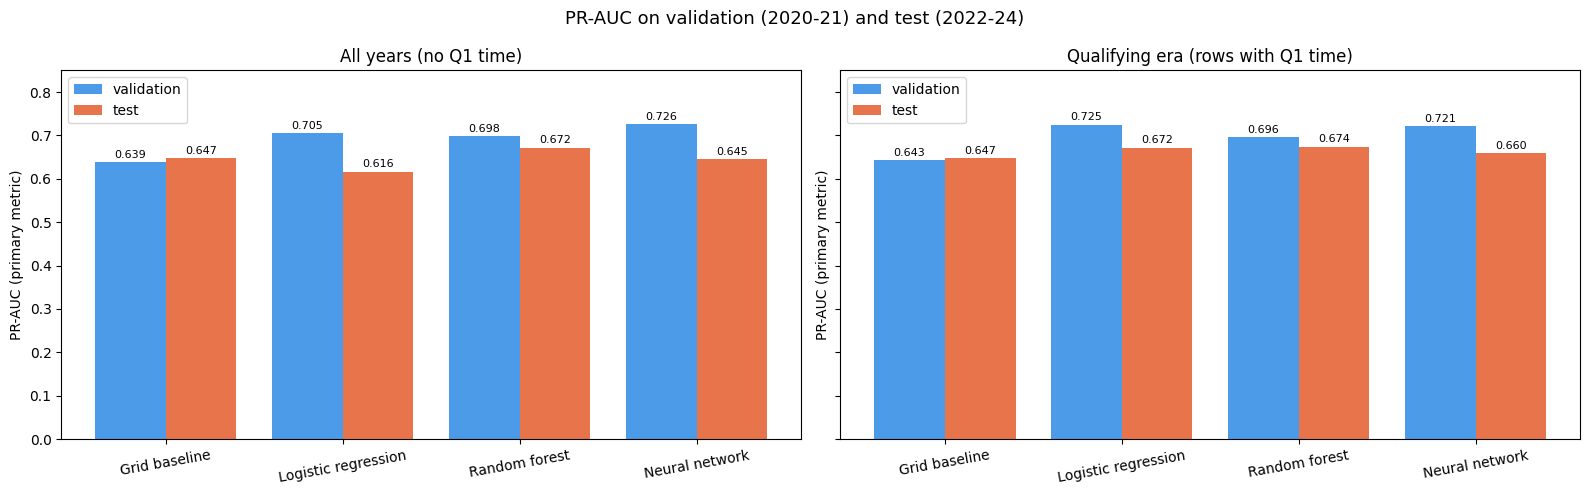

,table,model,train PR-AUC,val PR-AUC,val ROC-AUC,val F1,val Precision,val Recall,val Accuracy,test PR-AUC,test ROC-AUC,test F1,test Precision,test Recall,test Accuracy,test PR-AUC vs baseline
0,All years (no Q1 time),Grid baseline,0.495,0.639,0.909,0.692,0.692,0.692,0.908,0.647,0.914,0.649,0.650,0.647,0.895,0.000
1,All years (no Q1 time),Logistic regression,0.519,0.705,0.915,0.687,0.699,0.675,0.908,0.616,0.914,0.605,0.564,0.652,0.872,-0.031
2,All years (no Q1 time),Random forest,0.702,0.698,0.923,0.709,0.745,0.675,0.917,0.672,0.924,0.615,0.590,0.642,0.879,0.024
3,All years (no Q1 time),Neural network,0.608,0.726,0.918,0.687,0.621,0.769,0.895,0.645,0.921,0.630,0.514,0.814,0.857,-0.002
4,Qualifying era (rows with Q1 time),Grid baseline,0.602,0.643,0.916,0.695,0.692,0.698,0.908,0.647,0.913,0.649,0.650,0.647,0.894,0.000
5,Qualifying era (rows with Q1 time),Logistic regression,0.672,0.725,0.927,0.708,0.677,0.741,0.908,0.672,0.926,0.615,0.578,0.657,0.875,0.024
6,Qualifying era (rows with Q1 time),Random forest,0.865,0.696,0.924,0.698,0.698,0.698,0.909,0.674,0.928,0.629,0.581,0.686,0.877,0.027
7,Qualifying era (rows with Q1 time),Neural network,0.713,0.721,0.927,0.704,0.657,0.759,0.904,0.660,0.923,0.644,0.573,0.735,0.877,0.012


In [32]:
MODEL_ORDER = ['Grid baseline', 'Logistic regression', 'Random forest', 'Neural network']
rows = []
for (title, name), result in model_results.items():
    m = result['metrics']
    rows.append({
        'table': title, 'model': name,
        'train PR-AUC': m.loc['train', 'PR-AUC'],
        **{f'{split_name} {metric}': m.loc[split, metric]
           for split, split_name in [('val', 'val'), ('test', 'test')]
           for metric in ['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall', 'Accuracy']},
    })
comparison_table = pd.DataFrame(rows)
comparison_table['model'] = pd.Categorical(comparison_table['model'], MODEL_ORDER, ordered=True)
comparison_table = comparison_table.sort_values(['table', 'model']).reset_index(drop=True)
baseline_test = comparison_table[comparison_table['model'] == 'Grid baseline'].set_index('table')['test PR-AUC']
comparison_table['test PR-AUC vs baseline'] = comparison_table['test PR-AUC'] - comparison_table['table'].map(baseline_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (title, group) in zip(axes, comparison_table.groupby('table', sort=False)):
    x = np.arange(len(group))
    ax.bar(x - 0.2, group['val PR-AUC'], 0.4, label='validation', color='#4c9be8')
    ax.bar(x + 0.2, group['test PR-AUC'], 0.4, label='test', color='#e8744c')
    for i, (v, t) in enumerate(zip(group['val PR-AUC'], group['test PR-AUC'])):
        ax.text(i - 0.2, v + 0.01, f'{v:.3f}', ha='center', fontsize=8)
        ax.text(i + 0.2, t + 0.01, f'{t:.3f}', ha='center', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(group['model'].astype(str), rotation=10)
    ax.set_ylim(0, 0.85); ax.set_title(title); ax.set_ylabel('PR-AUC (primary metric)')
    ax.legend()
fig.suptitle('PR-AUC on validation (2020-21) and test (2022-24)', fontsize=13)
fig.tight_layout()
plt.show()

comparison_table.round(3)

**What the comparison shows**

- **Validation overstates the gain, and the test set corrects it.** On validation every model beats the grid baseline by 0.06–0.08 PR-AUC. On the 2022–2024 test seasons the gap shrinks to +0.012 to +0.029 PR-AUC on the qualifying-era table. The test seasons start a new technical era, and the 2020–21 validation seasons were dominated by the same teams as training, so form features transfer less well to the new rules.
- **The qualifying-era table is the better table.** With Q1 pace, the random forest (0.676), logistic regression (0.672) and neural network (0.660) all beat the baseline on test. Without it (all-years table) none of them does (0.616–0.643 vs 0.647): the extra pre-1994 history adds rows from very different eras rather than signal for the modern grid.
- **Final model: logistic regression on the qualifying-era table**, chosen the same way as every other setting, by **validation** PR-AUC (0.725, ahead of the network at 0.721 and the random forest at 0.702). On test it scores 0.672 PR-AUC and 0.926 ROC-AUC. The random forest happens to score slightly higher on test (0.676), but choosing it for that reason would use the test set for model selection; with a validation standard error of about 0.04 the three models are statistically tied. The neural network does not justify its extra complexity here.
- **Overfitting:** the random forest's training PR-AUC (0.88) is far above its validation score (0.70); depth 12 trees memorise the training seasons, although the validation-selected setting still generalises best. The linear model and the network show small train–validation gaps.
- **Thresholds:** as yes/no classifiers the models are not better than the rule "podium if grid ≤ 3" (test F1 0.615–0.649 vs 0.649). The models' value is in **ranking** drivers (PR-AUC, ROC-AUC), for example to estimate podium chances for drivers starting outside the top three.

# 6. Experiments

## 6.1 Feature-group ablation

Section 4.7 justified each feature group **before** training with univariate evidence. The ablation measures each group's contribution **after** training: we remove one group at a time from the qualifying-era table, retrain all three models with the full protocol (same hyperparameter search, threshold and early stopping), and compare PR-AUC with the full feature set. A large drop means the group carries information the others cannot replace. Because grid and qualifying position are nearly redundant, we also remove both together.

Bootstrap standard error of validation PR-AUC: 0.042 (116 podiums in 771 validation rows)


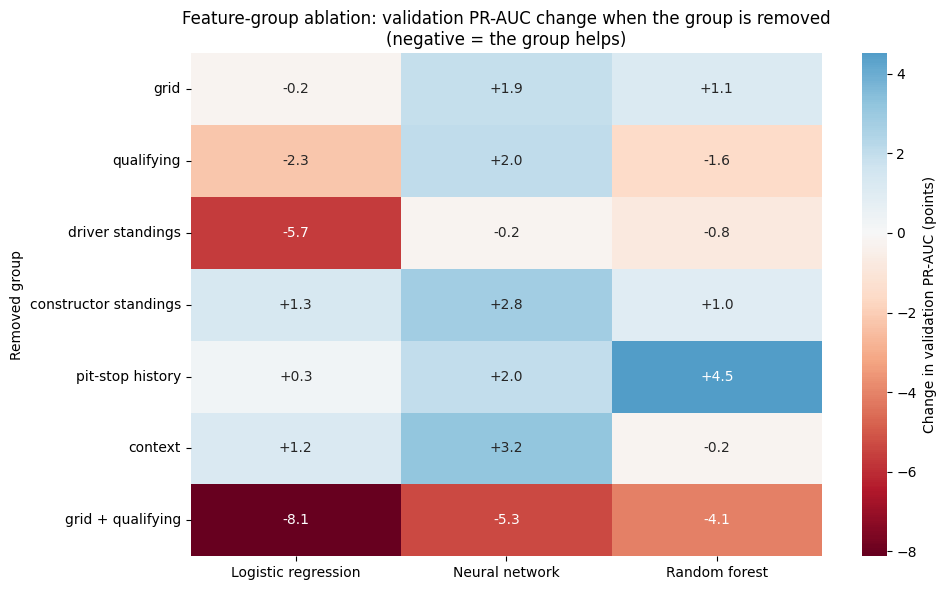

val PR-AUC                               \
model                 Logistic regression Neural network Random forest   
removed group                                                            
none (full model)                   0.725          0.721         0.696   
grid                                0.723          0.740         0.707   
qualifying                          0.702          0.741         0.680   
driver standings                    0.668          0.718         0.688   
constructor standings               0.738          0.749         0.706   
pit-stop history                    0.728          0.741         0.741   
context                             0.738          0.753         0.694   
grid + qualifying                   0.644          0.668         0.655   

                              test PR-AUC                               
model                 Logistic regression Neural network Random forest  
removed group                                                           
none (full model)                   0.672          0.660         0.674  
grid                                0.662          0.647         0.651  
qualifying                          0.644          0.643         0.660  
driver standings                    0.669          0.600         0.699  
constructor standings               0.676          0.666         0.665  
pit-stop history                    0.680          0.674         0.663  
context                             0.671          0.664         0.673  
grid + qualifying                   0.526          0.561         0.524

In [33]:
final_table = dropped_qual_time_rows
ABLATIONS = {name: cols for name, cols in FEATURE_GROUPS.items()}
ABLATIONS['grid + qualifying'] = FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying']
trainers = {
    'Logistic regression': train_logistic_regression_model,
    'Random forest': train_random_forest_model,
    'Neural network': train_neural_network_model,
}

ablation_rows = []
for model_name, trainer in trainers.items():
    full = model_results[(datasets[1][3], model_name)]['metrics']
    ablation_rows.append({'model': model_name, 'removed group': 'none (full model)',
                          'val PR-AUC': full.loc['val', 'PR-AUC'], 'test PR-AUC': full.loc['test', 'PR-AUC']})
    for group_name, removed in ABLATIONS.items():
        num = [c for c in numeric_cols if c not in removed]
        cat = [c for c in categorical_cols if c not in removed]
        result = trainer(final_table, num, cat, f'without {group_name}')
        ablation_rows.append({'model': model_name, 'removed group': group_name,
                              'val PR-AUC': result['metrics'].loc['val', 'PR-AUC'],
                              'test PR-AUC': result['metrics'].loc['test', 'PR-AUC']})

ablation = pd.DataFrame(ablation_rows)
full_scores = ablation[ablation['removed group'] == 'none (full model)'].set_index('model')
ablation['val change'] = ablation['val PR-AUC'] - ablation['model'].map(full_scores['val PR-AUC'])
ablation['test change'] = ablation['test PR-AUC'] - ablation['model'].map(full_scores['test PR-AUC'])

# How noisy is validation PR-AUC? Bootstrap the 771 validation rows for the full logistic regression.
_, X_full, y_full, _ = prepare_splits(final_table, numeric_cols, categorical_cols, scale=True)
lr_full = model_results[(datasets[1][3], 'Logistic regression')]
val_prob = lr_full['predict'](X_full['val'])
boot_rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(300):
    idx = boot_rng.integers(0, len(val_prob), len(val_prob))
    if y_full['val'][idx].sum() > 0:
        boot.append(average_precision_score(y_full['val'][idx], val_prob[idx]))
val_se = np.std(boot)
print(f'Bootstrap standard error of validation PR-AUC: {val_se:.3f} '
      f'({int(y_full["val"].sum())} podiums in {len(val_prob)} validation rows)')

change = ablation[ablation['removed group'] != 'none (full model)'].pivot(index='removed group', columns='model', values='val change')
change = change.loc[list(ABLATIONS)]
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(change * 100, annot=True, fmt='+.1f', cmap='RdBu', center=0, ax=ax,
            cbar_kws={'label': 'Change in validation PR-AUC (points)'})
ax.set_title('Feature-group ablation: validation PR-AUC change when the group is removed\n(negative = the group helps)')
ax.set_ylabel('Removed group'); ax.set_xlabel('')
fig.tight_layout()
plt.show()

ablation.pivot(index='removed group', columns='model', values=['val PR-AUC', 'test PR-AUC']).loc[['none (full model)'] + list(ABLATIONS)].round(3)

**Reading the ablation**

The bootstrap standard error of validation PR-AUC is about 0.04 (only 116 podiums in 771 validation rows), so single changes of 1–3 points are within noise. Read the heatmap together with the test columns of the table.

- **Grid and qualifying together are essential.** Removing both costs 4.7–8.1 points on validation and 10–15 points on test for every model. Removed one at a time the loss is small, because grid and qualifying position carry almost the same information; qualifying (which includes the Q1 gap) is the more useful of the two, costing 1.7–2.8 test points when removed.
- **Driver standings matter for the linear model** (−5.7 validation points without them) and somewhat for the random forest; for the network the effect is inside the noise.
- **Constructor standings, pit-stop history and context add nothing measurable.** Removing any of them slightly *raises* the scores for all three models, on validation and on test (pit-stop history: +0.6 to +1.4 test points). Constructor standings overlap with driver standings (teammates share them), and pit-stop history is zero before 2011.
- We **keep the full feature set** for the final models because none of these gains is larger than the validation noise, and selecting features on such small differences would tune the model to the two validation seasons. Dropping pit-stop history and context is the first simplification to try with more validation data (Section 9).

## 6.2 Preprocessing-order experiments

Three experiments change only the **order** of preprocessing steps and keep everything else fixed (same rows, features and the hyperparameters selected in Section 5). Logistic regression and the neural network are used because both depend on scaling and imputation; scores are PR-AUC.

| # | Order A (used in this notebook) | Order B (alternative) | Why it could matter |
| --- | --- | --- | --- |
| 1 | split by season, then fit imputer/scaler on training seasons | fit imputer/scaler on all seasons, then split | B lets test-season statistics leak into preprocessing |
| 2 | impute missing values, then scale | scale, then impute | changes the mean/std the scaler sees when 61% of `q1_gap_pct` is missing (all-seasons table with Q1 gap) |
| 3 | fill missing qualifying position with the grid slot, then impute | generic median imputation only | domain fill before generic imputation; 60% of qualifying positions are missing in the all-seasons table |

In [34]:
def fit_and_score(X, y):
    """Train LR and NN with the Section 5 hyperparameters on prepared matrices; return val/test PR-AUC."""
    lr_params = model_results[(datasets[1][3], 'Logistic regression')]['params']
    nn_params = model_results[(datasets[1][3], 'Neural network')]['params']
    scores = {}
    lr = LogisticRegression(**lr_params, max_iter=2000).fit(X['train'], y['train'])
    for split in ['val', 'test']:
        scores[('Logistic regression', split)] = average_precision_score(y[split], lr.predict_proba(X[split])[:, 1])
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y['train'])
    net = build_network(X['train'].shape[1], nn_params)
    net.fit(X['train'].astype('float32'), y['train'], validation_data=(X['val'].astype('float32'), y['val']),
            epochs=150, batch_size=32, class_weight={0: weights[0], 1: weights[1]}, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    for split in ['val', 'test']:
        scores[('Neural network', split)] = average_precision_score(y[split], net(X[split].astype('float32'), training=False).numpy().ravel())
    return scores


def transform_with(preprocessor, data, features, fit_on):
    parts = dict(zip(['train', 'val', 'test'], split_by_season(data)))
    preprocessor.fit(fit_on[features])
    X = {name: preprocessor.transform(part[features]) for name, part in parts.items()}
    y = {name: part['podium'].to_numpy() for name, part in parts.items()}
    return X, y


order_results = {}

# Experiment 1: split-then-fit vs fit-then-split (qualifying-era table)
features_q = numeric_cols + categorical_cols
train_q = split_by_season(final_table)[0]
X, y = transform_with(make_preprocessor(numeric_cols, categorical_cols), final_table, features_q, fit_on=train_q)
order_results[('1: split then fit (A)')] = fit_and_score(X, y)
X, y = transform_with(make_preprocessor(numeric_cols, categorical_cols), final_table, features_q, fit_on=final_table)
order_results[('1: fit on all seasons, then split (B)')] = fit_and_score(X, y)

# Experiment 2: impute-then-scale vs scale-then-impute (all-seasons table that keeps q1_gap_pct with missing values)
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                     ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
train_all = split_by_season(modeling_data)[0]
for label, steps in [
    ('2: impute then scale (A)', [('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]),
    ('2: scale then impute (B)', [('scaler', StandardScaler()), ('imputer', SimpleImputer(strategy='median'))]),
]:
    pre = ColumnTransformer([('numerical', Pipeline(steps), numeric_cols), ('categorical', cat_pipe, categorical_cols)])
    X, y = transform_with(pre, modeling_data, features_q, fit_on=train_all)
    order_results[label] = fit_and_score(X, y)

# Experiment 3: grid fallback before imputation vs median imputation only (all-seasons table)
raw_qualifying_position = modeling_data[['raceId', 'driverId']].merge(
    cleaned_tables['qualifying'][['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='left')['position']
no_fallback = modeling_data.copy()
no_fallback['qualifying_position'] = raw_qualifying_position.to_numpy()
print(f'Qualifying position missing without the grid fallback: {no_fallback["qualifying_position"].isna().mean():.0%} of all-seasons rows')
features_all = numeric_cols_all_years + categorical_cols
for label, data in [('3: grid fallback, then impute (A)', modeling_data), ('3: median imputation only (B)', no_fallback)]:
    X, y = transform_with(make_preprocessor(numeric_cols_all_years, categorical_cols), data, features_all,
                          fit_on=split_by_season(data)[0])
    order_results[label] = fit_and_score(X, y)

order_table = pd.DataFrame(order_results).T
order_table.columns = pd.MultiIndex.from_tuples(order_table.columns, names=['model', 'split'])
order_table.round(4)

Qualifying position missing without the grid fallback: 60% of all-seasons rows


model                                 Logistic regression          \
split                                                 val    test   
1: split then fit (A)                              0.7251  0.6716   
1: fit on all seasons, then split (B)              0.7253  0.6718   
2: impute then scale (A)                           0.7056  0.6237   
2: scale then impute (B)                           0.7054  0.6236   
3: grid fallback, then impute (A)                  0.7046  0.6161   
3: median imputation only (B)                      0.7183  0.6441   

model                                 Neural network          
split                                            val    test  
1: split then fit (A)                         0.7208  0.6595  
1: fit on all seasons, then split (B)         0.7133  0.6442  
2: impute then scale (A)                      0.7015  0.6389  
2: scale then impute (B)                      0.7096  0.6373  
3: grid fallback, then impute (A)             0.7255  0.6453  
3: median imputation only (B)                 0.7280  0.6542

**What the order experiments show**

1. **Split then fit vs fit then split:** practically no difference for logistic regression (0.7251 vs 0.7253 validation PR-AUC) and a small, noise-level change for the network. Standardization statistics barely move when two or three extra seasons are added, so the leak is tiny here. We still fit on training seasons only, because the correct order costs nothing and the leak would grow with stronger preprocessing (target encoding, feature selection).
2. **Impute then scale vs scale then impute:** identical for logistic regression (a linear model absorbs the shift) and within noise for the network (0.7015 vs 0.7116 validation). Order does not matter for median imputation plus standardization here.
3. **Grid fallback vs median imputation for missing qualifying position** (all-seasons table): the generic median imputation is **better** for both models (logistic regression 0.7046 → 0.7183 validation, 0.616 → 0.644 test). With the fallback, 60% of the rows carry a copy of `grid` in `qualifying_position`, so the model cannot tell real qualifying results from proxies; with median imputation those rows are neutral and the weight is learned from real qualifying data. This only affects the all-seasons table: in the qualifying-era table used for the final models every row has a real qualifying position, so the fallback never fires.

# 7. Model Explainability (XAI)

We explain the three final models (qualifying-era table) on the **2022–2024 test seasons**.

**Explaining the original features, not one-hot columns.** Each model has its own fitted preprocessor (the random forest's has no scaling), so explanations must feed every model *its own* preprocessing. `RawFeatureModel` wraps preprocessor + model so that SHAP and LIME work on the 21 original columns: categorical columns are represented as integer codes, and when an explainer perturbs `nationality_constructor` it swaps the whole category instead of flipping single one-hot columns into impossible rows. All three models are explained on the same probability scale.

> **Importance is not causation.** Every method below describes how a *model* uses its inputs to make predictions. A feature being important to the model does **not** mean it causes podium finishes, and these explanations should not be read as "changing X would change the result". For example, a high `driver_points_before_race` does not cause a podium; it is a symptom of a fast car and driver, which also cause the podium.

In [35]:
class RawFeatureModel:
    """Preprocessor + model behind an interface that takes the original columns (categoricals as integer codes)."""

    def __init__(self, result, reference_data):
        self.result = result
        self.features = result['features']
        self.categorical = [c for c in self.features if c in CATEGORICAL]
        self.categories = {c: np.array(sorted(reference_data[c].dropna().astype(str).unique())) for c in self.categorical}
        self.categorical_indices = [self.features.index(c) for c in self.categorical]

    def encode(self, df):
        out = np.empty((len(df), len(self.features)), dtype=float)
        for j, column in enumerate(self.features):
            if column in self.categories:
                cats = self.categories[column]
                out[:, j] = np.clip(np.searchsorted(cats, df[column].astype(str).to_numpy()), 0, len(cats) - 1)
            else:
                out[:, j] = df[column].to_numpy(dtype=float)
        return out

    def decode(self, X):
        X = np.asarray(X, dtype=float)
        data = {}
        for j, column in enumerate(self.features):
            if column in self.categories:
                cats = self.categories[column]
                data[column] = cats[np.clip(np.rint(X[:, j]).astype(int), 0, len(cats) - 1)]
            else:
                data[column] = X[:, j]
        return pd.DataFrame(data, columns=self.features)

    def predict(self, X):
        transformed = self.result['preprocessor'].transform(self.decode(X))
        return np.concatenate([self.result['predict'](transformed[i:i + 20000]) for i in range(0, len(transformed), 20000)])

    def predict_proba(self, X):
        p = self.predict(X)
        return np.column_stack([1 - p, p])


FINAL_TITLE = datasets[1][3]
final_models = {name: model_results[(FINAL_TITLE, name)] for name in ['Logistic regression', 'Random forest', 'Neural network']}
xai_train, _, xai_test = split_by_season(final_table)
xai_test = xai_test.reset_index(drop=True)
wrappers = {name: RawFeatureModel(result, final_table) for name, result in final_models.items()}
feature_names = wrappers['Random forest'].features
X_train_raw = wrappers['Random forest'].encode(xai_train)
X_test_raw = wrappers['Random forest'].encode(xai_test)
y_test_xai = xai_test['podium'].to_numpy()

# Sanity check: the wrapper reproduces each model's own test PR-AUC from Section 5
for name, wrapper in wrappers.items():
    print(f"{name}: test PR-AUC via wrapper {average_precision_score(y_test_xai, wrapper.predict(X_test_raw)):.3f} "
          f"(Section 5: {final_models[name]['metrics'].loc['test', 'PR-AUC']:.3f})")

Logistic regression: test PR-AUC via wrapper 0.672 (Section 5: 0.672)
Random forest: test PR-AUC via wrapper 0.674 (Section 5: 0.674)
Neural network: test PR-AUC via wrapper 0.660 (Section 5: 0.660)


## 7.1 Global: permutation importance

For each original feature, shuffle its values across the test rows (breaking its link with the outcome while keeping its distribution), and measure the drop in test PR-AUC. Repeated 10 times; bars show the mean and error bars the standard deviation.

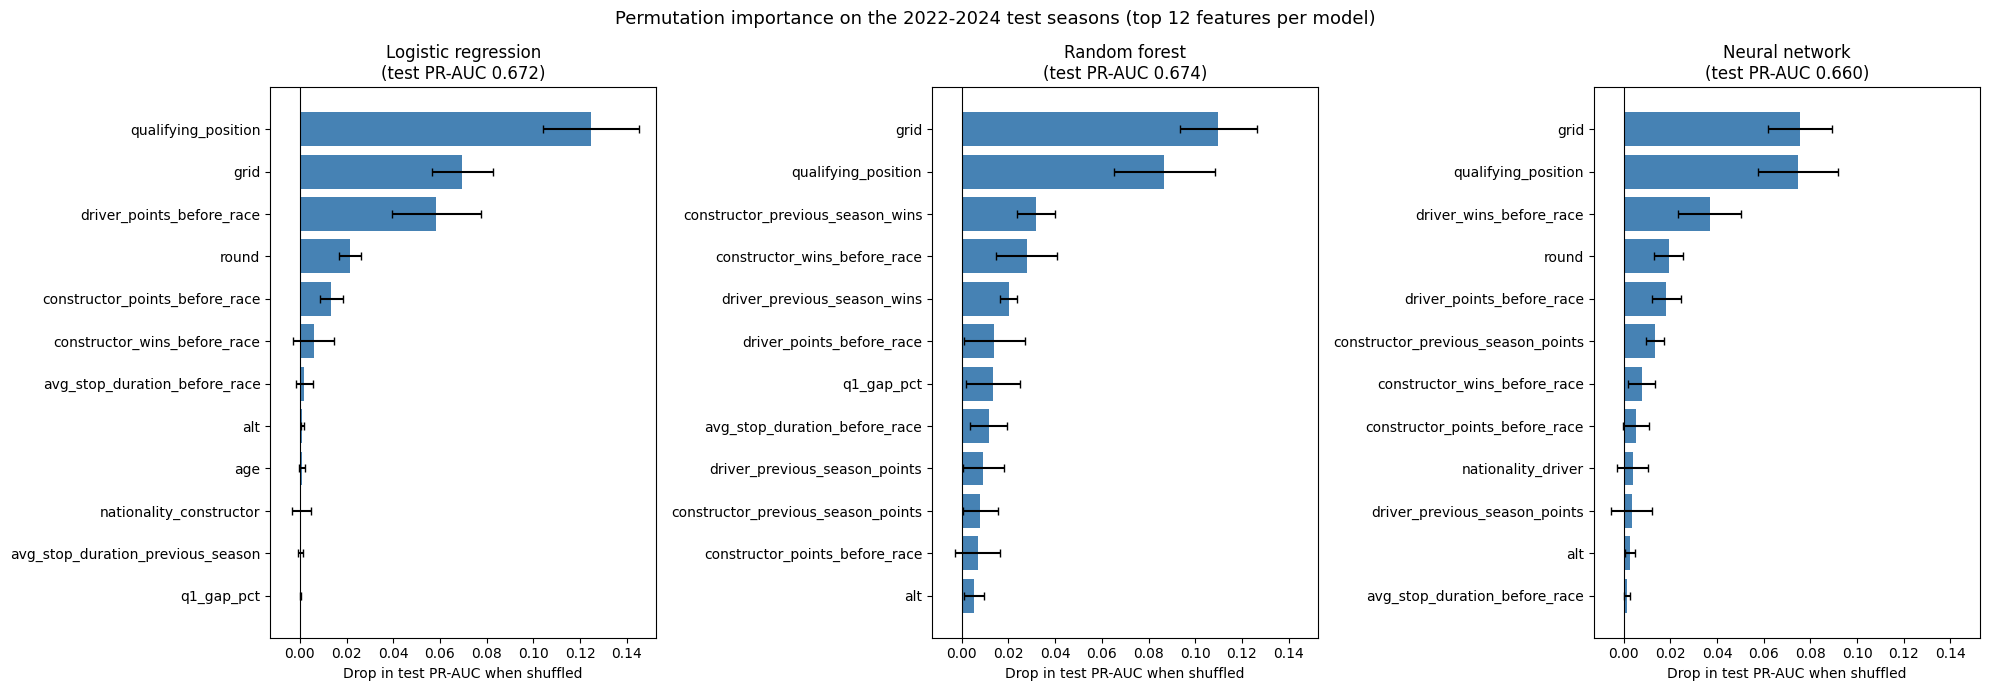

,Logistic regression,Random forest,Neural network
grid,0.070,0.110,0.076
qualifying_position,0.125,0.087,0.075
constructor_previous_season_wins,-0.000,0.032,-0.002
constructor_wins_before_race,0.006,0.028,0.008
driver_previous_season_wins,-0.002,0.020,-0.002
driver_points_before_race,0.058,0.014,0.018
q1_gap_pct,0.000,0.013,0.000
avg_stop_duration_before_race,0.002,0.012,0.002
driver_previous_season_points,-0.005,0.009,0.004
constructor_previous_season_points,-0.003,0.008,0.013


In [36]:
def permutation_importance_raw(wrapper, X, y, n_repeats=10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    baseline = average_precision_score(y, wrapper.predict(X))
    drops = np.zeros((X.shape[1], n_repeats))
    for j in range(X.shape[1]):
        for r in range(n_repeats):
            X_perm = X.copy()
            X_perm[:, j] = rng.permutation(X_perm[:, j])
            drops[j, r] = baseline - average_precision_score(y, wrapper.predict(X_perm))
    return pd.DataFrame({'mean': drops.mean(axis=1), 'std': drops.std(axis=1)}, index=wrapper.features), baseline


perm_importance = {}
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharex=True)
for ax, (name, wrapper) in zip(axes, wrappers.items()):
    imp, baseline = permutation_importance_raw(wrapper, X_test_raw, y_test_xai)
    perm_importance[name] = imp['mean']
    top = imp.sort_values('mean').tail(12)
    ax.barh(top.index, top['mean'], xerr=top['std'], color='steelblue', capsize=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{name}\n(test PR-AUC {baseline:.3f})')
    ax.set_xlabel('Drop in test PR-AUC when shuffled')
fig.suptitle('Permutation importance on the 2022-2024 test seasons (top 12 features per model)', fontsize=13)
fig.tight_layout()
plt.show()

pd.DataFrame(perm_importance).sort_values('Random forest', ascending=False).round(3)

## 7.2 Global: SHAP

SHAP splits each prediction into additive contributions, one per feature, measured against the average prediction over a background sample of 100 training rows. We use the model-agnostic permutation explainer on the original features for all three models, so the values are directly comparable (units: podium probability, or score for the class-weighted models). The beeswarm shows one dot per test row: position on the x-axis is the contribution, colour is the feature's value. For the three categorical columns the colour is an arbitrary category code and should be ignored. The bar chart compares the mean absolute contribution across models.

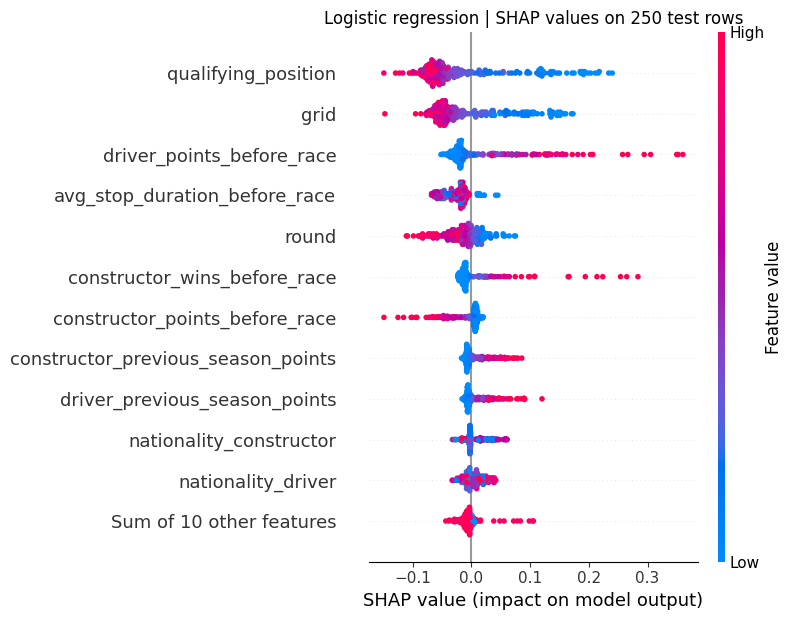

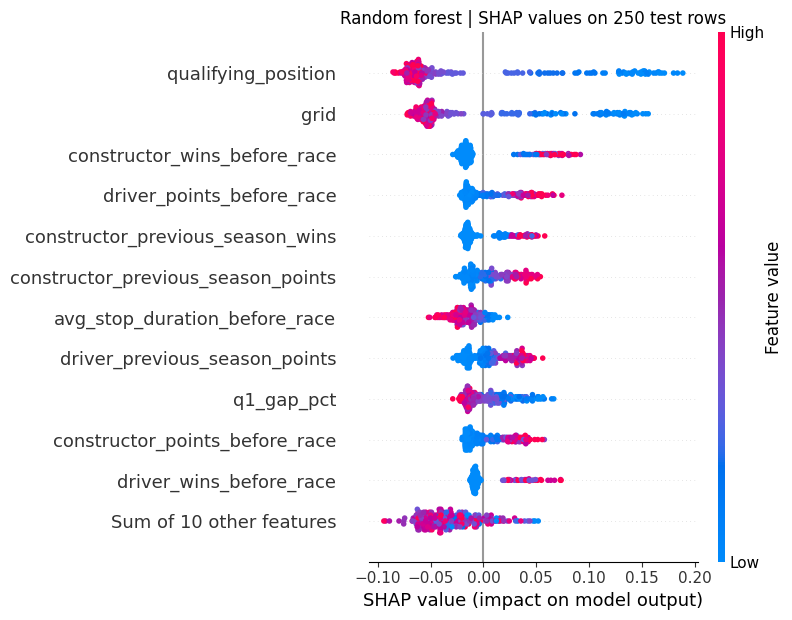

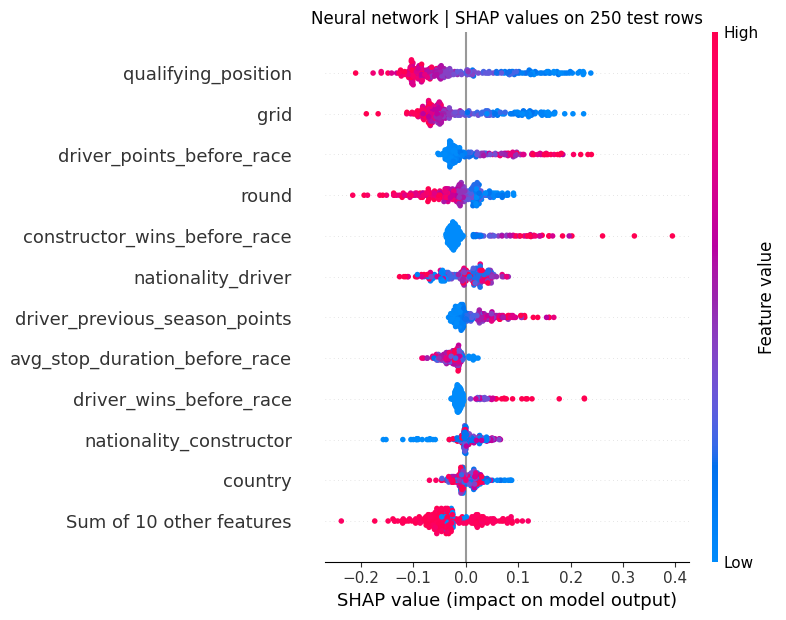

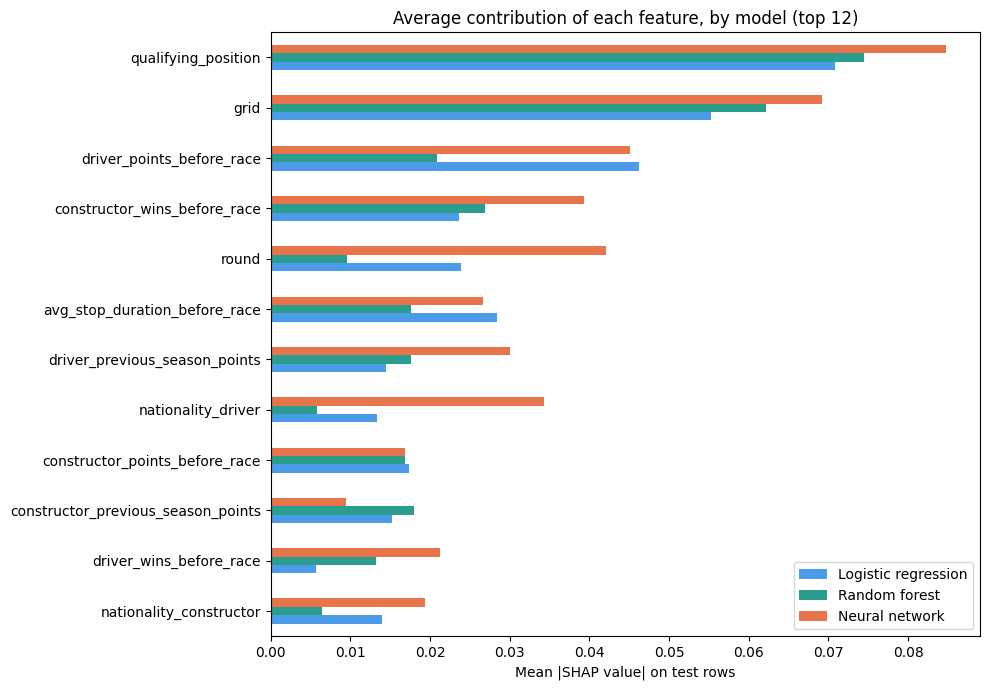

,Logistic regression,Random forest,Neural network
qualifying_position,0.0709,0.0745,0.0848
grid,0.0552,0.0621,0.0692
driver_points_before_race,0.0462,0.0209,0.0450
constructor_wins_before_race,0.0237,0.0268,0.0393
round,0.0239,0.0096,0.0420
avg_stop_duration_before_race,0.0284,0.0177,0.0266
driver_previous_season_points,0.0145,0.0176,0.0301
nationality_driver,0.0133,0.0058,0.0343
constructor_points_before_race,0.0174,0.0168,0.0169
constructor_previous_season_points,0.0153,0.0179,0.0094


In [37]:
shap_rng = np.random.default_rng(RANDOM_STATE)
background = X_train_raw[shap_rng.choice(len(X_train_raw), 100, replace=False)]
shap_rows = shap_rng.choice(len(X_test_raw), 250, replace=False)
n_features = len(feature_names)

shap_values = {}
explainers = {}
for name, wrapper in wrappers.items():
    explainers[name] = shap.Explainer(wrapper.predict, shap.maskers.Independent(background),
                                      feature_names=feature_names, algorithm='permutation', seed=RANDOM_STATE)
    values = explainers[name](X_test_raw[shap_rows], max_evals=4 * n_features + 2, silent=True)
    values.display_data = wrappers[name].decode(X_test_raw[shap_rows]).to_numpy(dtype=object)
    shap_values[name] = values

for name, values in shap_values.items():
    plt.figure()
    shap.plots.beeswarm(values, max_display=12, show=False)
    plt.title(f'{name} | SHAP values on 250 test rows')
    plt.tight_layout()
    plt.show()

mean_abs = pd.DataFrame({name: np.abs(v.values).mean(axis=0) for name, v in shap_values.items()}, index=feature_names)
mean_abs = mean_abs.loc[mean_abs.mean(axis=1).sort_values(ascending=False).index]
ax = mean_abs.head(12).iloc[::-1].plot(kind='barh', figsize=(10, 7), color=['#4c9be8', '#2a9d8f', '#e8744c'])
ax.set_xlabel('Mean |SHAP value| on test rows')
ax.set_title('Average contribution of each feature, by model (top 12)')
plt.tight_layout()
plt.show()
mean_abs.round(4).head(12)

## 7.3 Local explanations: two single predictions

We explain two test rows from the 2024 season with **LIME** for all three models and a **SHAP waterfall** for the random forest, whose tree structure makes its local trade-offs easy to see:

- **A typical case:** Lando Norris (McLaren), Abu Dhabi 2024, started from pole and won.
- **A surprise:** Max Verstappen (Red Bull), São Paulo 2024, started 17th after a grid penalty and won. Pre-race information pointed the other way, so this shows how the models reason when they are wrong.

**LIME** fits a small linear model around one row, using thousands of perturbed copies of it, and reports the conditions (such as `grid <= 4.00`) that push this one prediction up or down. Categorical columns are perturbed as whole categories. **SHAP waterfall** starts from the average prediction and adds each feature's contribution until it reaches this row's prediction.


=== Norris, Abu Dhabi 2024 (grid 1, won) ===
grid                                     1
qualifying_position                    1.0
q1_gap_pct                        0.456172
driver_points_before_race            349.0
constructor_points_before_race       640.0
positionOrder                            1


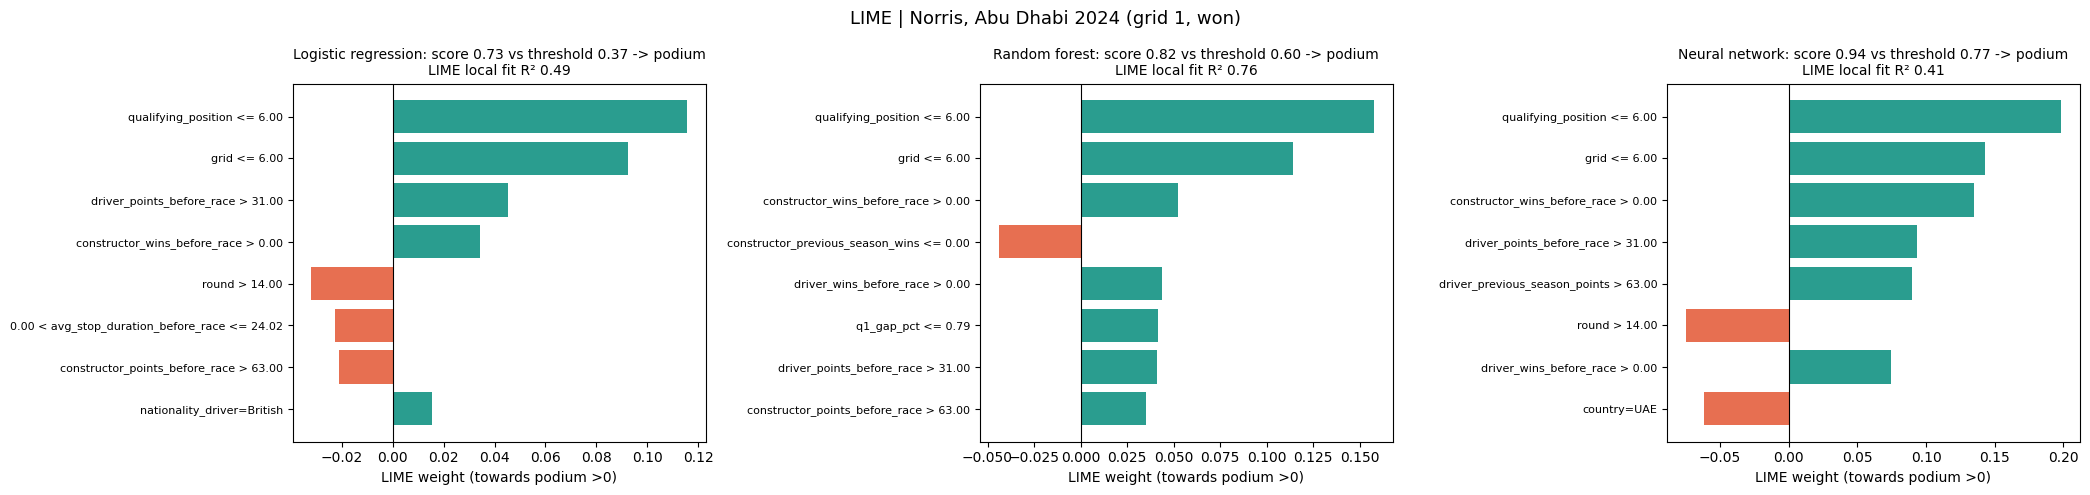

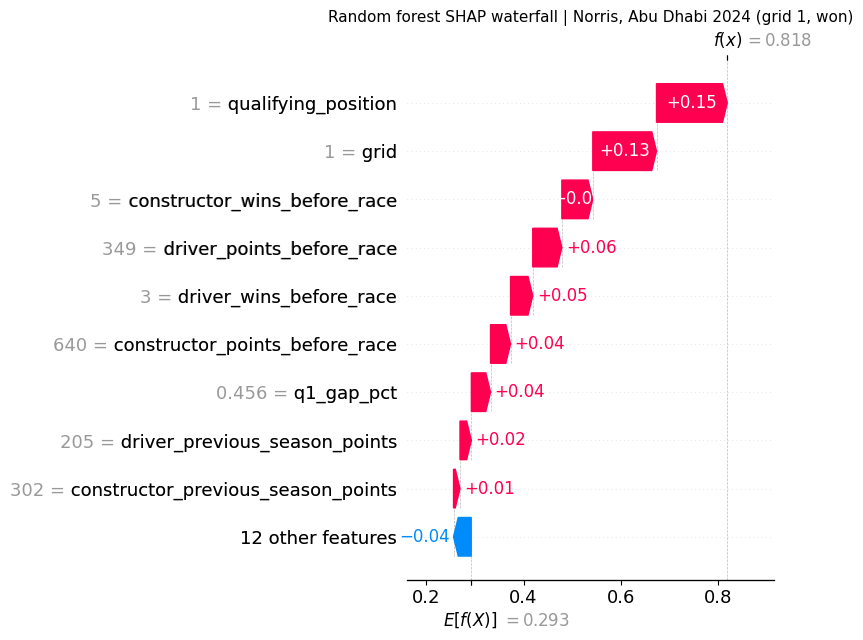


=== Verstappen, Sao Paulo 2024 (grid 17, won) ===
grid                                 17
qualifying_position                12.0
q1_gap_pct                          0.0
driver_points_before_race         362.0
constructor_points_before_race    512.0
positionOrder                         1


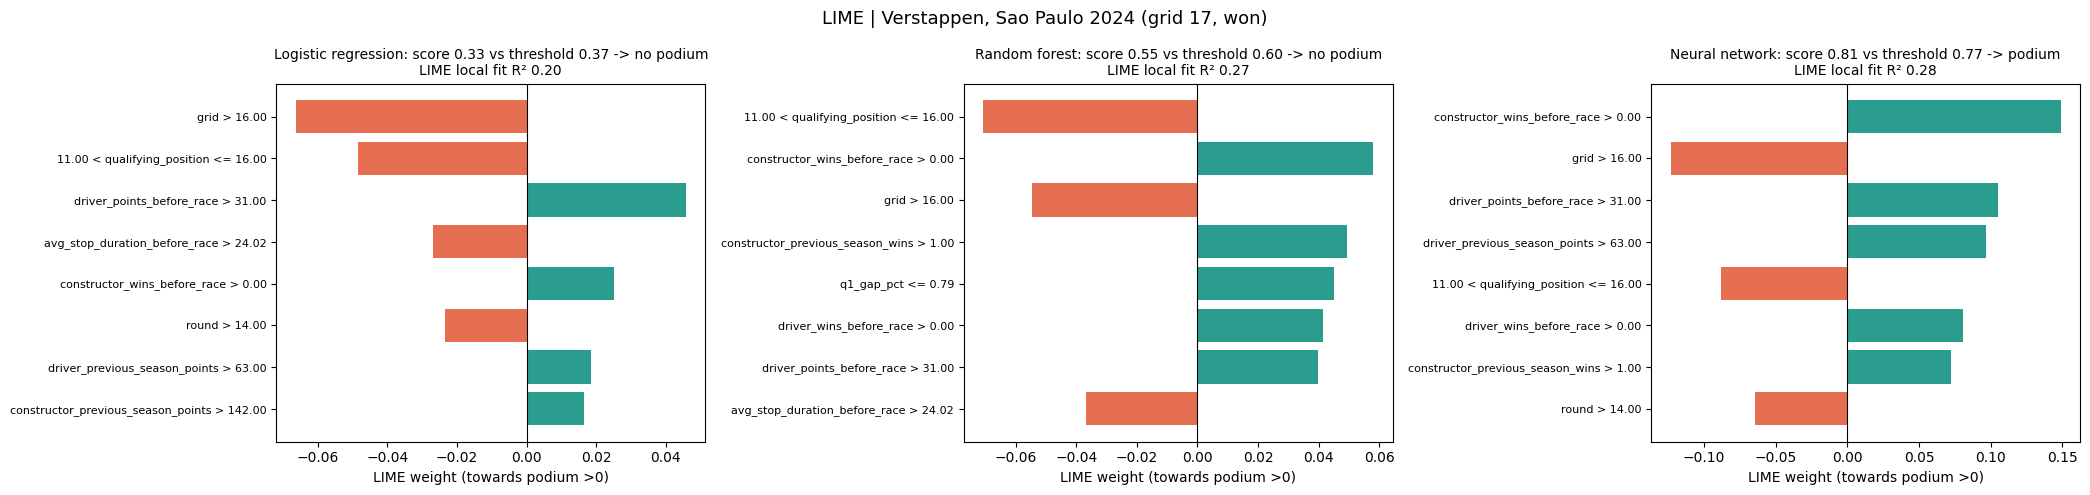

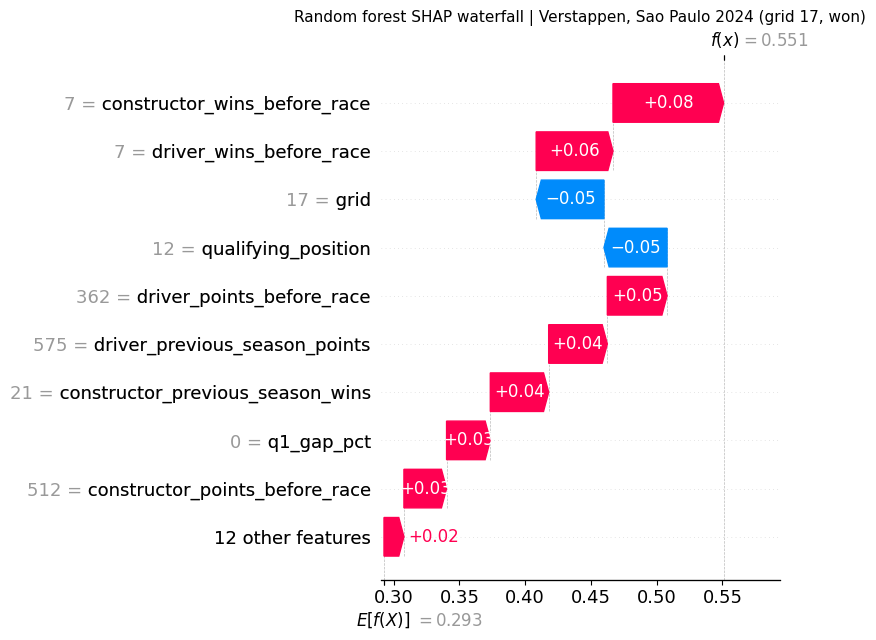

In [38]:
def find_test_row(race_id, driver_id):
    match = xai_test.index[(xai_test['raceId'] == race_id) & (xai_test['driverId'] == driver_id)]
    if len(match) == 0:
        raise ValueError(f'race {race_id}, driver {driver_id} is not in the test rows of the final table')
    return int(match[0])


local_cases = {
    'Norris, Abu Dhabi 2024 (grid 1, won)': find_test_row(1144, 846),
    'Verstappen, Sao Paulo 2024 (grid 17, won)': find_test_row(1141, 830),
}

lime_explainer = LimeTabularExplainer(
    training_data=X_train_raw, feature_names=feature_names, class_names=['No podium', 'Podium'],
    categorical_features=wrappers['Random forest'].categorical_indices,
    categorical_names={wrappers['Random forest'].features.index(c): list(cats)
                       for c, cats in wrappers['Random forest'].categories.items()},
    mode='classification', discretize_continuous=True, random_state=RANDOM_STATE,
)

for case, row in local_cases.items():
    x_row = X_test_raw[row]
    facts = xai_test.loc[row, ['grid', 'qualifying_position', 'q1_gap_pct', 'driver_points_before_race',
                               'constructor_points_before_race', 'positionOrder']]
    print(f'\n=== {case} ===')
    print(facts.to_string())

    fig, axes = plt.subplots(1, 3, figsize=(21, 5))
    for ax, (name, wrapper) in zip(axes, wrappers.items()):
        prob = wrapper.predict(x_row[None])[0]
        threshold = final_models[name]['threshold']
        exp = lime_explainer.explain_instance(x_row, wrapper.predict_proba, num_features=8, num_samples=5000, labels=(1,))
        items = exp.as_list(label=1)[::-1]
        ax.barh([k for k, _ in items], [v for _, v in items], color=['#2a9d8f' if v > 0 else '#e76f51' for _, v in items])
        ax.axvline(0, color='black', lw=0.8)
        verdict = 'podium' if prob >= threshold else 'no podium'
        ax.set_title(f'{name}: score {prob:.2f} vs threshold {threshold:.2f} -> {verdict}\n'
                     f'LIME local fit R² {exp.score:.2f}', fontsize=10)
        ax.set_xlabel('LIME weight (towards podium >0)')
        ax.tick_params(axis='y', labelsize=8)
    fig.suptitle(f'LIME | {case}', fontsize=13)
    fig.tight_layout()
    plt.show()

    rf_row = explainers['Random forest'](x_row[None], max_evals=4 * n_features + 2, silent=True)[0]
    rf_row.display_data = wrappers['Random forest'].decode(x_row[None]).to_numpy(dtype=object)[0]
    plt.figure()
    shap.plots.waterfall(rf_row, max_display=10, show=False)
    plt.title(f'Random forest SHAP waterfall | {case}', fontsize=11)
    plt.tight_layout()
    plt.show()

**Interpretation**

*Global (permutation importance and SHAP agree on the big picture).*

- **Starting position dominates every model.** Shuffling `qualifying_position` or `grid` costs 0.07–0.125 test PR-AUC, far more than any other feature, and both have the largest mean |SHAP| in all three models. In the random-forest beeswarm, a front-row slot (blue, low values) adds up to +0.19 to the score, while a midfield or back-row slot subtracts 0.05–0.10.
- **Season form comes second, and each model uses it differently.** Logistic regression leans on `driver_points_before_race` (0.058 PR-AUC drop); the random forest spreads its reliance over the constructor's wins this season and last season (0.02–0.03); the network uses `driver_wins_before_race` (0.037). High values of these features always push towards a podium.
- **Some features move predictions without improving them.** `avg_stop_duration_before_race` and `round` have visible SHAP values in the linear model and the network (mean |SHAP| 0.02–0.04) but almost no permutation importance. The models use them (`round` helps scale season-to-date points, which grow during a season), yet they do not improve ranking on the test seasons, matching the ablation result that pit-stop history and context add nothing measurable.
- **Nationality, country, altitude and age matter very little** (permutation importance at or below 0.005 for every model).
- **Why the two methods differ in detail:** SHAP measures how much a feature *moves the output*; permutation importance measures how much *ranking quality* is lost without it. Correlated features (grid and qualifying position, the standings family) share credit in SHAP but can replace each other when one is shuffled.

*Local.*

- **Norris, Abu Dhabi 2024 (pole, won):** all three models predict a podium (scores 0.73, 0.82, 0.94, all above their thresholds). LIME's strongest reasons are the same for each model, `qualifying_position <= 6` and `grid <= 6`, followed by the team's wins this season. The random-forest LIME fit is good (R² 0.78), so this explanation is reliable.
- **Verstappen, São Paulo 2024 (17th on the grid, won):** logistic regression (0.33) and the random forest (0.63) stay below their thresholds and predict *no podium*; the network (0.81) predicts a podium. The waterfall shows the trade-off: the poor grid (−0.05) and qualifying position (−0.05) are outweighed in the forest by strong form (7 wins this season for driver and team, +0.15 together), lifting the score from the 0.32 average to 0.63, but not past 0.72. The network gives form more weight, which is why it alone was right here. LIME's local fit is weak for this unusual row (R² 0.20–0.29), so its bars are only a rough guide.

These explanations describe the models' behaviour, **not causes**: starting near the front is strongly associated with podiums because fast cars qualify well *and* finish well, and the models learned that association.

# 8. Inference Function

`predict_podium` takes one driver–race record as it would be known after qualifying and returns the podium probability (score) and the yes/no decision of a final model. The default is logistic regression, the final model chosen on validation (Section 5.6); the other two can be selected with `model_name`.

- **Required:** `raceId` (the race must be in the calendar, `races.csv`), `driverId`, `constructorId`. These identify the race and give access to the standings and history *before* that race.
- **Optional:** `grid`, `qualifying_position` and `q1` (seconds or a lap-time string such as `'1:22.595'`).
- **Missing values** are handled exactly as in training: a missing qualifying position falls back to the grid slot, and anything still missing (for example `q1_gap_pct` when no Q1 time is given, or `grid`) is filled with the training median by the model's own fitted preprocessor. The function reports which inputs were imputed.
- All features are rebuilt with `build_modeling_table`, the same function used for training, so the inference features match the training features exactly.

In [39]:
def predict_podium(record, model_name='Logistic regression'):
    """Predict whether a driver finishes on the podium, from information available after qualifying."""
    required = ['raceId', 'driverId', 'constructorId']
    missing_required = [key for key in required if record.get(key) is None]
    if missing_required:
        raise ValueError(f'Missing required fields: {missing_required}')
    if record['raceId'] not in set(cleaned_tables['races']['raceId']):
        raise ValueError(f"Unknown raceId {record['raceId']}")
    if model_name not in final_models:
        raise ValueError(f'model_name must be one of {list(final_models)}')

    entry = pd.DataFrame([{
        'raceId': record['raceId'], 'driverId': record['driverId'], 'constructorId': record['constructorId'],
        'grid': record.get('grid', np.nan),
        'qualifying_position': record.get('qualifying_position', np.nan),
        'q1': to_seconds(record.get('q1', np.nan)),
        'q2': np.nan, 'q3': np.nan,
    }]).astype({'grid': float, 'qualifying_position': float, 'q1': float})

    row = build_modeling_table(entry)
    model = final_models[model_name]
    features = model['features']
    imputed = [f for f in features if pd.isna(row[f].iloc[0])]
    fallback = pd.isna(record.get('qualifying_position', np.nan)) and not pd.isna(record.get('grid', np.nan))

    score = float(model['predict'](model['preprocessor'].transform(row[features]))[0])
    return {
        'model': model_name,
        'podium_score': round(score, 3),
        'threshold': round(model['threshold'], 3),
        'predicted_podium': score >= model['threshold'],
        'imputed_by_model': imputed,
        'qualifying_position_from_grid': fallback,
        'features': row[features].iloc[0],
    }


# Demonstration: Lando Norris, 2024 Abu Dhabi Grand Prix (raceId 1144), taken from the cleaned tables
demo_result = cleaned_tables['results'].query('raceId == 1144 and driverId == 846').iloc[0]
demo_quali = cleaned_tables['qualifying'].query('raceId == 1144 and driverId == 846').iloc[0]

complete_record = {
    'raceId': 1144, 'driverId': 846, 'constructorId': int(demo_result['constructorId']),
    'grid': int(demo_result['grid']), 'qualifying_position': int(demo_quali['position']),
    'q1': float(demo_quali['q1']),
}
partial_record = {  # the grid is known, but the qualifying feed (position and Q1 time) is missing
    'raceId': 1144, 'driverId': 846, 'constructorId': int(demo_result['constructorId']),
    'grid': int(demo_result['grid']),
}

outputs = {}
for label, record in [('complete record', complete_record), ('partially missing record', partial_record)]:
    print(f'--- {label}: {record}')
    for model_name in final_models:
        out = predict_podium(record, model_name)
        outputs[(label, model_name)] = out
        print(f"  {model_name:20s} score {out['podium_score']:.3f} vs threshold {out['threshold']:.3f} -> "
              f"{'PODIUM' if out['predicted_podium'] else 'no podium'}"
              + (f"; imputed: {out['imputed_by_model']}" if out['imputed_by_model'] else ''))

print('\nActual result: finished P' + str(int(demo_result['positionOrder'])))
pd.DataFrame({label: outputs[(label, 'Random forest')]['features'] for label in ['complete record', 'partially missing record']})

--- complete record: {'raceId': 1144, 'driverId': 846, 'constructorId': 1, 'grid': 1, 'qualifying_position': 1, 'q1': 83.682}
  Logistic regression  score 0.726 vs threshold 0.368 -> PODIUM
  Random forest        score 0.818 vs threshold 0.603 -> PODIUM
  Neural network       score 0.939 vs threshold 0.772 -> PODIUM
--- partially missing record: {'raceId': 1144, 'driverId': 846, 'constructorId': 1, 'grid': 1}
  Logistic regression  score 0.722 vs threshold 0.368 -> PODIUM; imputed: ['q1_gap_pct']
  Random forest        score 0.721 vs threshold 0.603 -> PODIUM; imputed: ['q1_gap_pct']
  Neural network       score 0.941 vs threshold 0.772 -> PODIUM; imputed: ['q1_gap_pct']

Actual result: finished P1


,complete record,partially missing record
grid,1.0,1.0
qualifying_position,1.0,1.0
q1_gap_pct,0.456172,NaN
driver_points_before_race,349.0,349.0
driver_wins_before_race,3,3
driver_previous_season_points,205.0,205.0
driver_previous_season_wins,0,0
constructor_points_before_race,640.0,640.0
constructor_wins_before_race,5,5
constructor_previous_season_points,302.0,302.0


**Result.** For the complete record (pole position, Q1 time 0.46% off the fastest) all three models predict a podium, and Norris did win. When the qualifying feed is missing but the grid is known, the qualifying position falls back to the grid slot and only `q1_gap_pct` is imputed with the training median; the scores barely move (random forest 0.818 → 0.791) and the decision stays the same. Note that if the grid itself were unknown, it would be imputed with the training median (around 11th), which would understate a front-runner's chances, so the grid should always be supplied in practice.

# 9. Known Limitations

- **Qualifying-coverage drift.** Qualifying data starts in 1994 and is complete only from 2003. The final models therefore use 1994+ rows with a Q1 time; the all-seasons table without qualifying pace did not beat the grid baseline on test.
- **Era sensitivity.** F1 changes its technical rules every few years. Validation (2020–21) belongs to the turbo-hybrid era while test (2022–24) belongs to the ground-effect era, and the models' advantage over the grid baseline shrinks from about 0.07 PR-AUC on validation to 0.01–0.03 on test. Expect further drops when the rules change again (2026).
- **Small validation set.** Only 116 podiums in 771 validation rows; the bootstrap standard error of validation PR-AUC is about 0.04. Hyperparameter, threshold and feature choices made on validation are therefore noisy, which is why we did not drop feature groups on the basis of 1–3 point ablation gains.
- **Points systems change.** Season points (10 for a win until 2009, 25 since 2010) make raw points features not comparable across eras; tree models cannot extrapolate beyond the ranges seen in training. Points shares or standings positions would be more stable.
- **Identity drift.** Constructor renames (Toro Rosso → AlphaTauri → RB) reset team history; nationality is only a weak proxy for team identity.
- **Pit-stop history** exists only from 2011 and is set to zero before; it adds nothing measurable and is the first group to drop.
- **Probabilities are scores.** Class weighting (random forest, neural network) shifts outputs upward, so a score of 0.8 is not an 80% chance; calibration (Platt or isotonic on validation) would be needed before reporting probabilities.
- **Sprint races** are not used. From 2021 the sprint happens before the main race and is technically pre-race information that could improve predictions on sprint weekends.
- **Non-causal explanations.** Importance and SHAP values describe the models, not why drivers reach the podium.